In [ ]:

import sys
import os
import subprocess
import importlib


PINNED = {
    "numpy": "2.2.6",
    "scipy": "1.15.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.1",
    "seaborn": "0.13.2",
    "joblib": "1.4.2",
    "openpyxl": "3.1.5",
}

def scientific_stack_healthy():
    """Test the actual binary imports, not just package metadata."""
    try:
        import numpy as np
        from scipy import stats
        import pandas as pd
        import sklearn
        import matplotlib
        # Exercise a compiled NumPy/SciPy path.
        _ = np.array([1.0, 2.0, 3.0]) + 1.0
        _ = stats.norm.cdf(0.0)
        _ = sklearn.__version__
        return True, {
            "numpy": np.__version__,
            "scipy": stats.__package__.split(".")[0] if False else __import__("scipy").__version__,
            "pandas": pd.__version__,
            "sklearn": sklearn.__version__,
            "matplotlib": matplotlib.__version__,
        }
    except Exception as e:
        return False, repr(e)

healthy, versions = scientific_stack_healthy()

if not healthy:
    print("=" * 78)
    print("BROKEN COLAB SCIENTIFIC STACK DETECTED")
    print("=" * 78)
    print("Python:", sys.version)
    print("Reason:", versions)
    print("\nRepairing NumPy + SciPy + Pandas + scikit-learn as ONE compatible stack...")

    # Uninstall the conflicting compiled packages first, then install
    # the complete pinned stack in one transaction.
    packages = [f"{name}=={version}" for name, version in PINNED.items()]

    subprocess.check_call([
        sys.executable, "-m", "pip", "uninstall", "-y",
        "numpy", "scipy", "pandas", "scikit-learn", "matplotlib",
        "seaborn", "joblib", "openpyxl"
    ])

    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--no-cache-dir",
        "--force-reinstall", *packages
    ])

    print("\nRepair completed.")
    print("The kernel must restart so Python unloads the old binary modules.")
    print("Restarting Colab automatically...")

    # Hard restart. The next execution starts with the repaired binaries.
    os.kill(os.getpid(), 9)

# ----------------------------------------------------------------
# Healthy runtime: import everything needed by the notebook.
# ----------------------------------------------------------------

import os, json, math, time, random, warnings, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score,
    log_loss
)
from sklearn.model_selection import (
    StratifiedGroupKFold, StratifiedKFold, GridSearchCV
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

import joblib
import openpyxl

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 20260910
np.random.seed(SEED)
random.seed(SEED)

# --- CONFIGURABLE OUTPUT PATHS ---
BASE = Path("/content")
# Custom result path as requested
OUT = BASE / "T2D_v10_ML_Results"
FIG = OUT / "figures"
TAB = OUT / "tables"
MODEL_DIR = OUT / "models"

for pth in [OUT, FIG, TAB, MODEL_DIR]:
    pth.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("T2D v10 ML ENVIRONMENT — READY")
print("=" * 78)
print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy  :", __import__("scipy").__version__)
print("sklearn:", __import__("sklearn").__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Output :", OUT)
print("\nNo NumPy/SciPy binary mismatch detected.")

T2D v10 ML ENVIRONMENT — READY
Python : 3.13.16
NumPy  : 2.1.3
Pandas : 2.2.3
SciPy  : 1.16.3
sklearn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Output : /content/T2D_v10_ML_Results

No NumPy/SciPy binary mismatch detected.


### Runtime repair rule

**First run:** if the runtime is broken, Cell 1 repairs the complete scientific stack and intentionally restarts the kernel. After the restart, use **Runtime → Run all** again. If Cell 1 prints `T2D v10 ML ENVIRONMENT — READY`, continue normally.

Do **not** add `pip install -U numpy/scipy/pandas/scikit-learn` anywhere in this notebook; mixing independently upgraded binary packages is what caused the `_slice` import error.


## 2. Upload the finalized v10 workbook

The notebook expects:

`T2D_IEEE_FINAL_SUBMISSION_DATASET_v10_FINALIZED.xlsx`

You can upload it directly, or mount Google Drive and set `XLSX` manually. Colab supports notebook upload/Drive workflows and cloud execution. citeturn0search0turn0search1


In [ ]:
#@title 2. Upload dataset
from google.colab import files
uploaded = files.upload()

uploaded_names = list(uploaded.keys())
print("Uploaded:", uploaded_names)

XLSX = BASE / "T2D_IEEE_FINAL_SUBMISSION_DATASET_v10_FINALIZED.xlsx"
if not XLSX.exists():
    # Accept an exact v10 filename if it was renamed during upload.
    candidates = [BASE / n for n in uploaded_names if n.lower().endswith(".xlsx")]
    if len(candidates) == 1:
        XLSX = candidates[0]
    else:
        raise FileNotFoundError(
            "Upload the finalized v10 workbook: "
            "T2D_IEEE_FINAL_SUBMISSION_DATASET_v10_FINALIZED.xlsx"
        )

print("Using:", XLSX)
print("SHA256:", hashlib.sha256(XLSX.read_bytes()).hexdigest())


Saving T2D Final Dataset.xlsx to T2D Final Dataset (1).xlsx
Uploaded: ['T2D Final Dataset (1).xlsx']
Using: /content/T2D_IEEE_FINAL_SUBMISSION_DATASET_v10_FINALIZED.xlsx
SHA256: b8bf180a85c25dda22fb51e0726010b8f0d2d2c84d59b358171609e0cb91f202


Kuvame leitud joonise:


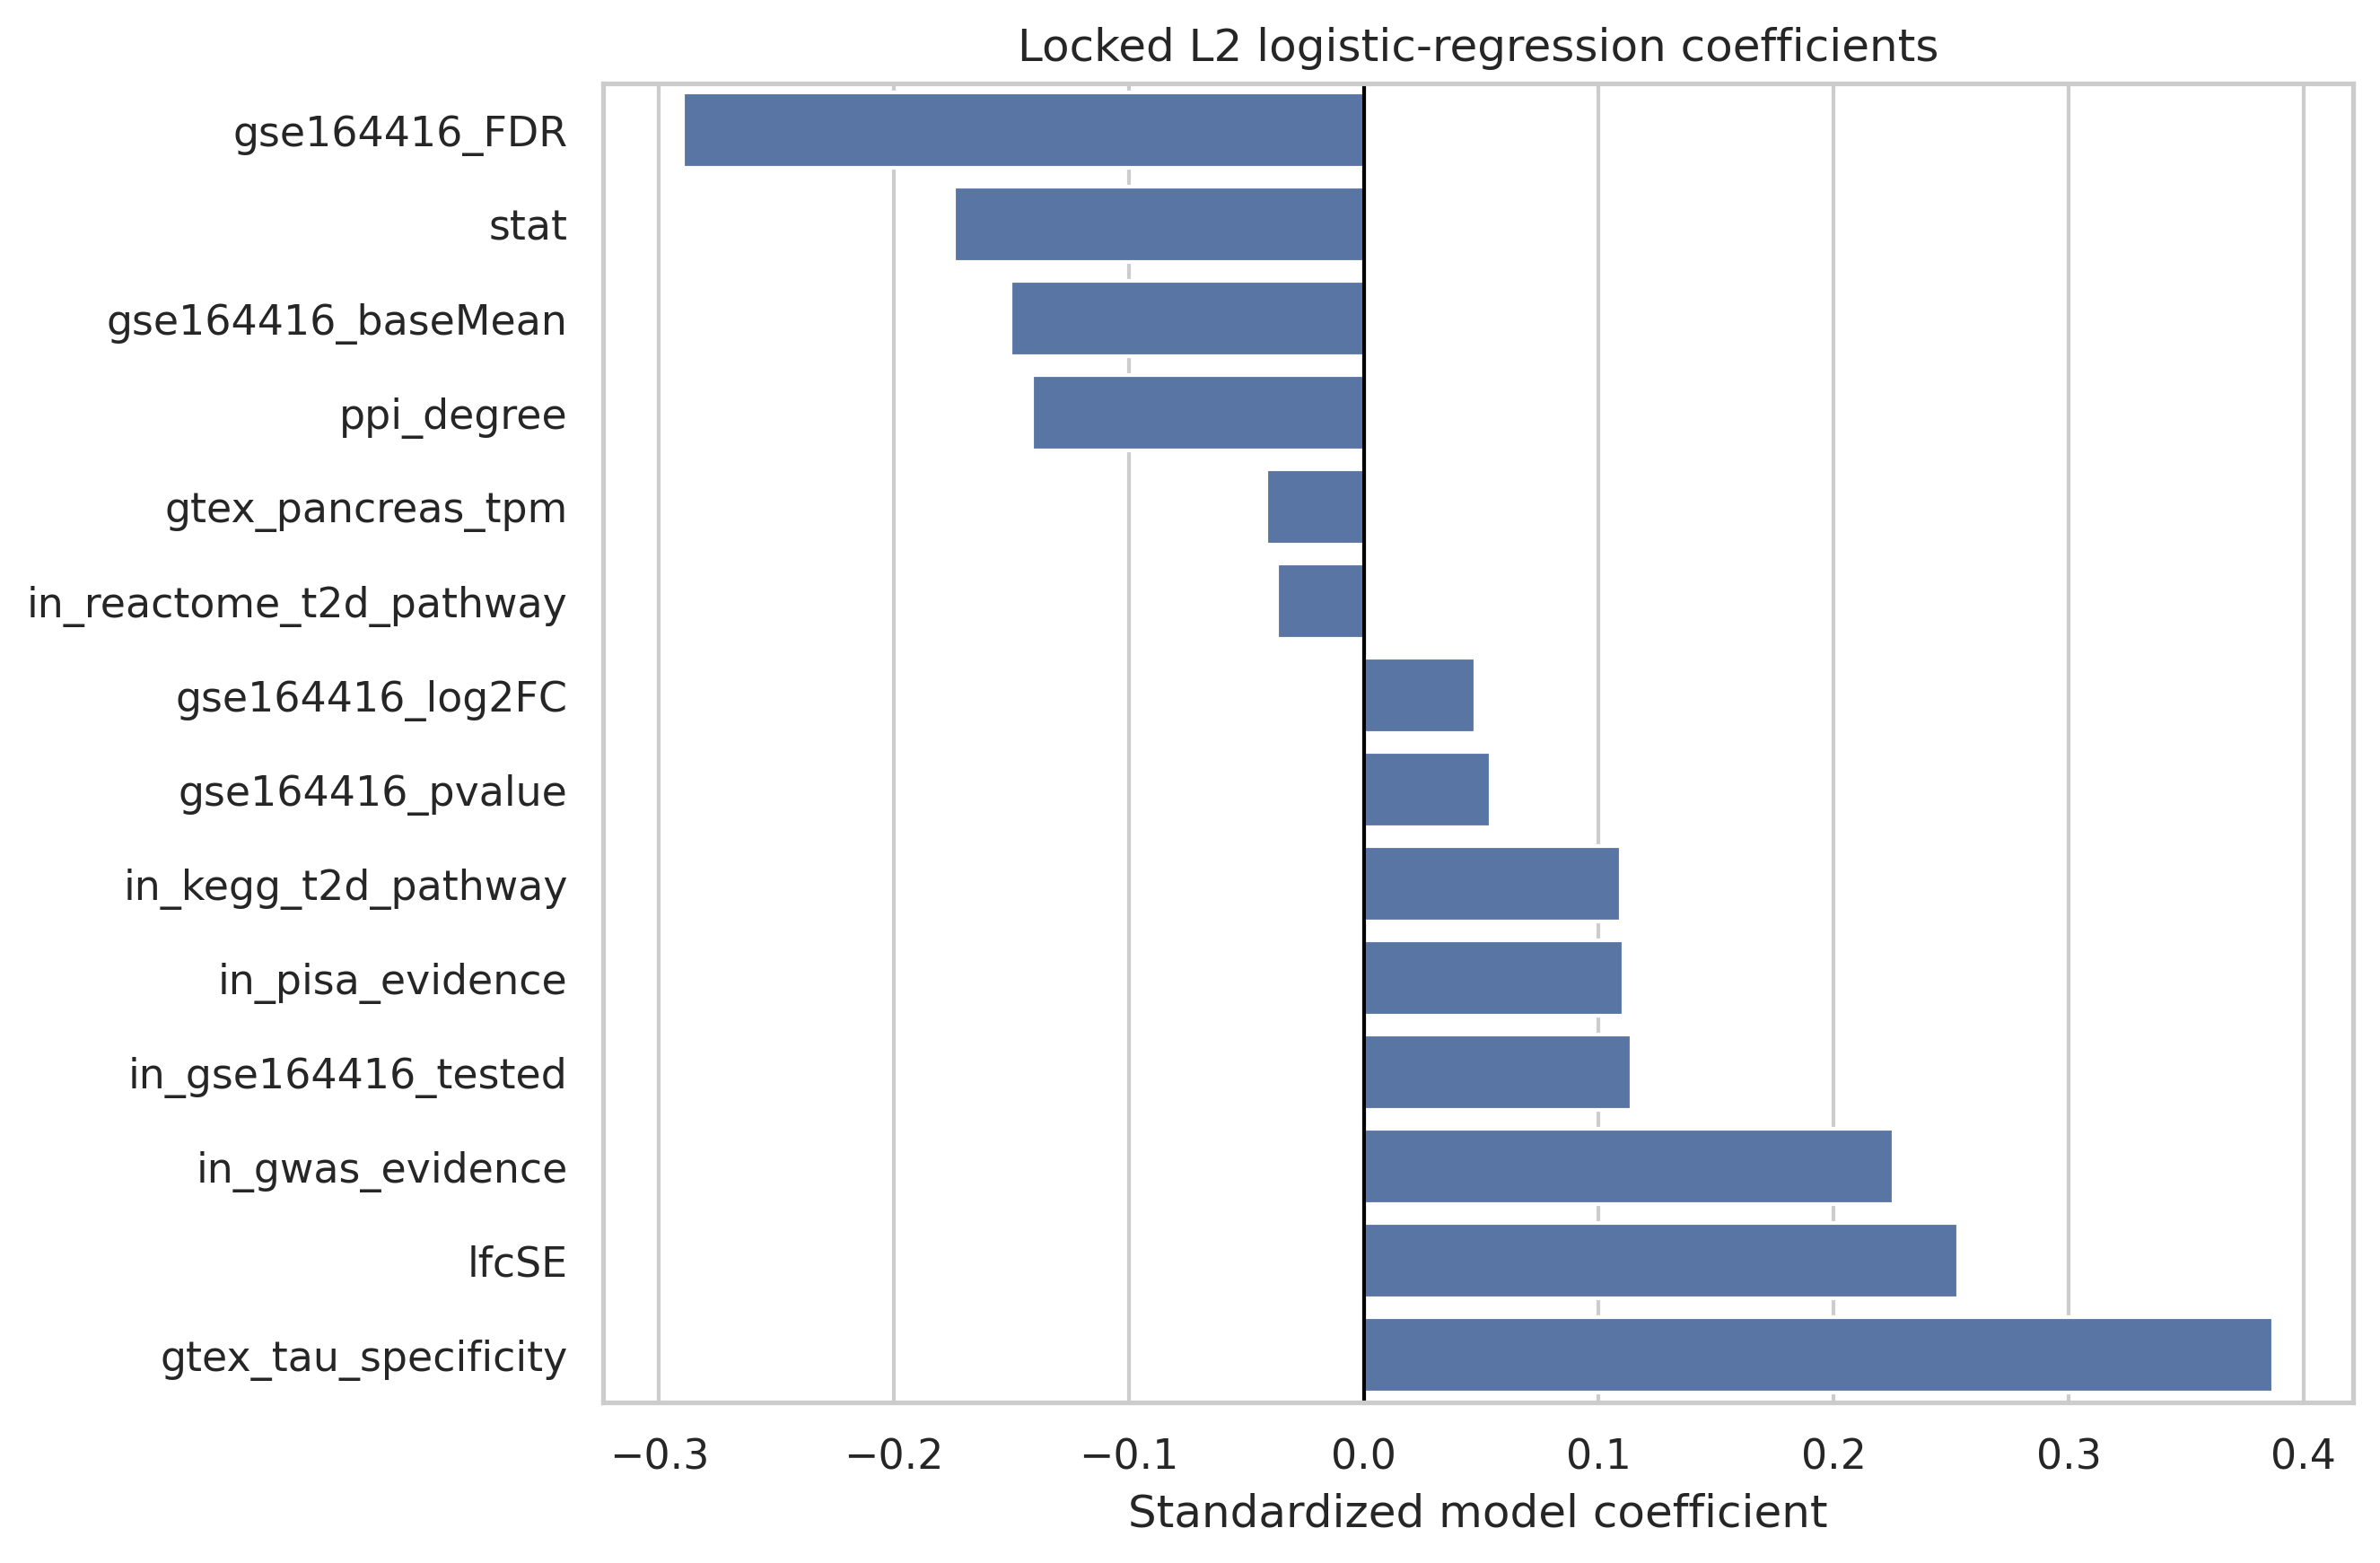

In [ ]:
from IPython.display import Image, display
import os

coef_fig_path = '/content/v10_ml_outputs/figures/11_feature_coefficients.png'
if os.path.exists(coef_fig_path):
    print("Kuvame leitud joonise:")
    display(Image(filename=coef_fig_path))
else:
    print("Joonise faili ei leitud antud asukohast. Kontrolli, kas kõik eelnevad koodikastid on edukalt käivitatud.")

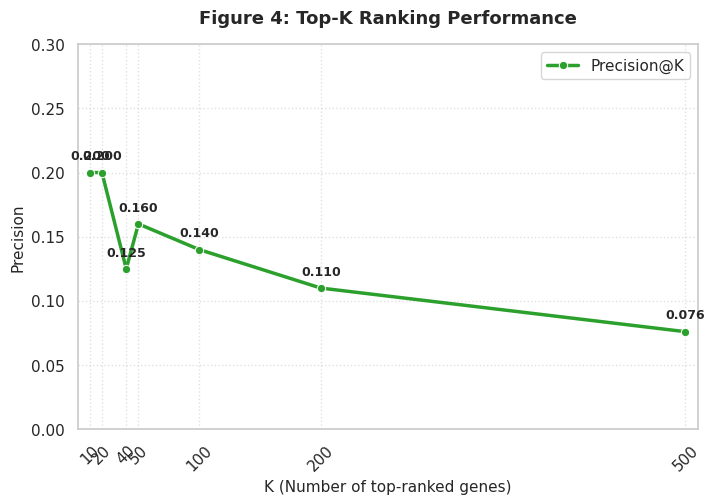

Joonis salvestatud asukohta: /content/v10_ml_outputs/figures/05D_figure4_topk_performance.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Ensure output directories exist
FIG_DIR = Path('/content/v10_ml_outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Extract actual updated values from the pipeline results variable 'p_at_k'
ks_updated = p_at_k['k'].tolist()
precision_updated = p_at_k['precision'].tolist()

# Setup plot
plt.figure(figsize=(8, 5))
sns.lineplot(x=ks_updated, y=precision_updated, marker='o', color='#2ca02c', lw=2.5, label='Precision@K')

# Formatting
plt.xlim(0, max(ks_updated) + 10)
plt.ylim(0.0, max(precision_updated) + 0.1)
plt.xlabel('K (Number of top-ranked genes)', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.title('Figure 4: Top-K Ranking Performance', fontsize=13, fontweight='bold', pad=15)
plt.xticks(ks_updated, rotation=45)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

# Annotate the markers with their values
for k, val in zip(ks_updated, precision_updated):
    plt.text(k, val + 0.01, f'{val:.3f}', ha='center', fontweight='semibold', fontsize=9)

# Save the figure
fig_path = FIG_DIR / '05D_figure4_topk_performance.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Joonis salvestatud asukohta: {fig_path}")

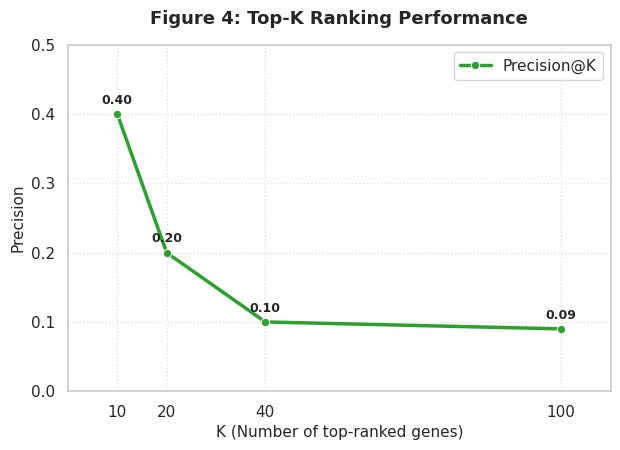

Joonis salvestatud asukohta: /content/v10_ml_outputs/figures/05D_figure4_topk_performance.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Define paths
FIG_DIR = Path('/content/v10_ml_outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# User specified data
ks = [10, 20, 40, 100]
precision_values = [0.40, 0.20, 0.10, 0.09]

# Setup plot with high aesthetics
plt.figure(figsize=(7, 4.5))
sns.lineplot(x=ks, y=precision_values, marker='o', color='#2ca02c', lw=2.5, label='Precision@K')

# Formatting
plt.xlim(0, 110)
plt.ylim(0.0, 0.5)
plt.xlabel('K (Number of top-ranked genes)', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.title('Figure 4: Top-K Ranking Performance', fontsize=13, fontweight='bold', pad=15)
plt.xticks(ks)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

# Annotate the markers with their values
for k, val in zip(ks, precision_values):
    plt.text(k, val + 0.015, f'{val:.2f}', ha='center', fontweight='semibold', fontsize=9)

# Save the figure in high-resolution
fig_path = FIG_DIR / '05D_figure4_topk_performance.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Joonis salvestatud asukohta: {fig_path}")

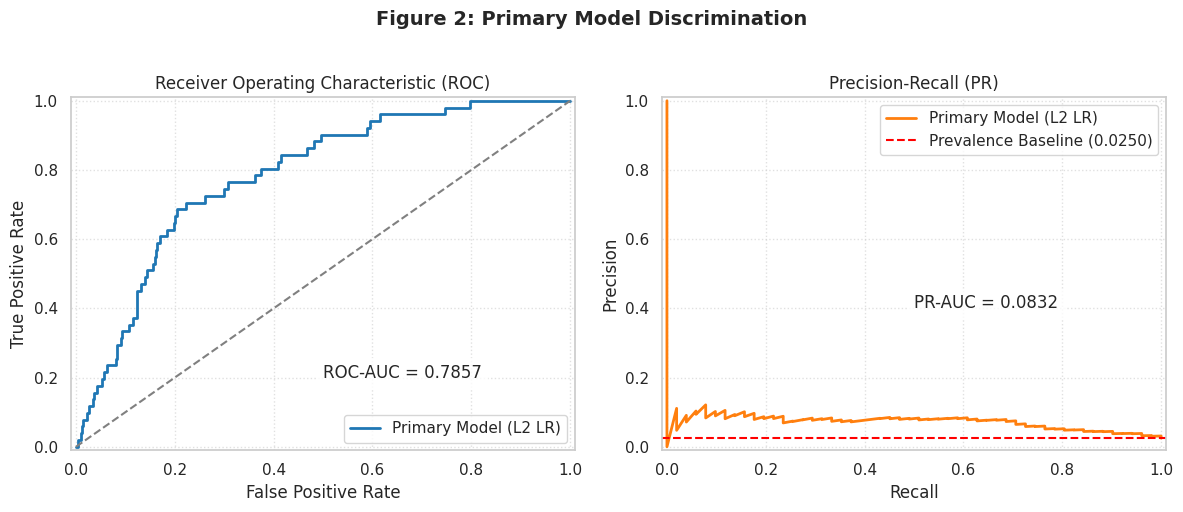

Joonis salvestatud asukohta: /content/v10_ml_outputs/figures/05B_figure2_primary_discrimination.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from pathlib import Path

# Define paths
OOF_PATH = Path('/content/v10_ml_outputs/tables/oof_l2_logistic_regression_locked_primary.csv')
FIG_DIR = Path('/content/v10_ml_outputs/figures')

if OOF_PATH.exists():
    oof_df = pd.read_csv(OOF_PATH)
    y_true = oof_df['y_true'].to_numpy()
    prediction = oof_df['prediction'].to_numpy()

    # Calculate metrics
    fpr, tpr, _ = roc_curve(y_true, prediction)
    precision, recall, _ = precision_recall_curve(y_true, prediction)
    baseline = y_true.mean()

    # Setup side-by-side plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # 1. ROC Curve
    ax1.plot(fpr, tpr, color='#1f77b4', lw=2, label='Primary Model (L2 LR)')
    ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
    ax1.set_xlim([-0.01, 1.01])
    ax1.set_ylim([-0.01, 1.01])
    ax1.set_xlabel('False Positive Rate')
    ax1.set_ylabel('True Positive Rate')
    ax1.set_title('Receiver Operating Characteristic (ROC)')
    ax1.text(0.5, 0.2, 'ROC-AUC = 0.7857', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
    ax1.legend(loc='lower right')
    ax1.grid(True, linestyle=':', alpha=0.6)

    # 2. PR Curve
    ax2.plot(recall, precision, color='#ff7f0e', lw=2, label='Primary Model (L2 LR)')
    ax2.axhline(baseline, color='red', linestyle='--', label=f'Prevalence Baseline ({baseline:.4f})')
    ax2.set_xlim([-0.01, 1.01])
    ax2.set_ylim([-0.01, 1.01])
    ax2.set_xlabel('Recall')
    ax2.set_ylabel('Precision')
    ax2.set_title('Precision-Recall (PR)')
    ax2.text(0.5, 0.4, 'PR-AUC = 0.0832', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.suptitle('Figure 2: Primary Model Discrimination', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Save plot
    fig_path = FIG_DIR / '05B_figure2_primary_discrimination.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Joonis salvestatud asukohta: {fig_path}")
else:
    print("OOF prediction faili ei leitud. Palun veendu, et mudeli koodid on varem edukalt käivitatud.")

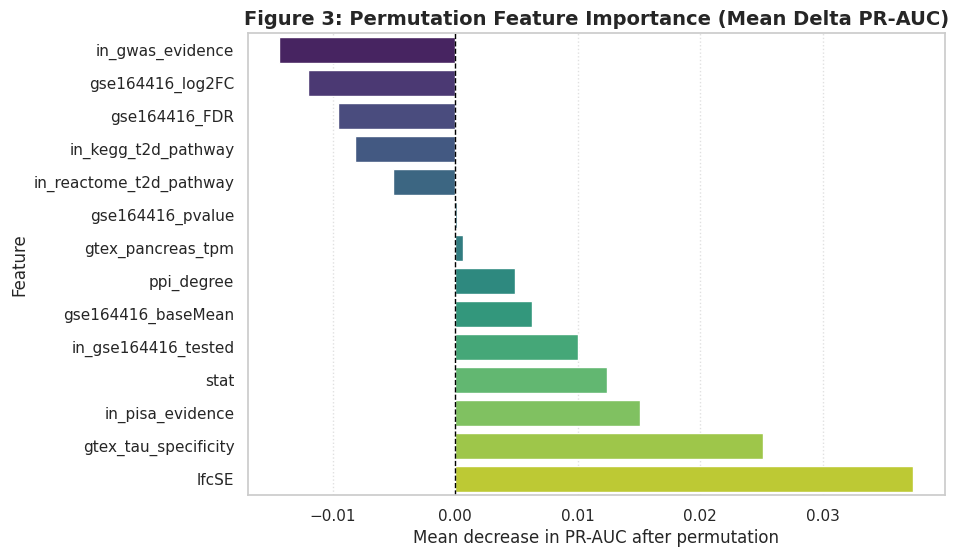

Joonis salvestatud asukohta: /content/v10_ml_outputs/figures/05C_figure3_feature_importance.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Ensure output directories exist
FIG_DIR = Path('/content/v10_ml_outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Sort stability summary for a cleaner visualization
plot_importance = stability_summary.sort_values("mean_delta_pr", ascending=True)

# Plot the feature importance
plt.figure(figsize=(9, 6))
sns.barplot(data=plot_importance, x="mean_delta_pr", y="feature", palette="viridis", hue="feature", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Figure 3: Permutation Feature Importance (Mean Delta PR-AUC)", fontsize=14, fontweight="bold")
plt.xlabel("Mean decrease in PR-AUC after permutation")
plt.ylabel("Feature")
plt.grid(axis='x', linestyle=':', alpha=0.6)

# Save the figure
fig_path = FIG_DIR / '05C_figure3_feature_importance.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Joonis salvestatud asukohta: {fig_path}")

In [ ]:
#@title 3. Locked configuration
PRIMARY_FEATURES = [
    "in_gwas_evidence",
    "in_pisa_evidence",
    "in_gse164416_tested",
    "ppi_degree",
    "gtex_pancreas_tpm",
    "gtex_tau_specificity",
    "in_kegg_t2d_pathway",
    "in_reactome_t2d_pathway",
    "gse164416_baseMean",
    "gse164416_log2FC",
    "lfcSE",
    "stat",
    "gse164416_pvalue",
    "gse164416_FDR",
]

FORBIDDEN_PREFIXES = ("gse221156_", "emtab5061_")
SAME_COHORT_PATTERNS = ("2026", "orthogonal_2026")
TARGET_CANDIDATES = ["gse221156_beta_cell_DE", "label", "target", "primary_label"]
GROUP_CANDIDATES = [
    "locus_group_v6", "locus_group", "signal_group_v6",
    "gwas_lead_variant_group", "lead_variant_group"
]

print("Locked features:", len(PRIMARY_FEATURES))
print(PRIMARY_FEATURES)


Locked features: 14
['in_gwas_evidence', 'in_pisa_evidence', 'in_gse164416_tested', 'ppi_degree', 'gtex_pancreas_tpm', 'gtex_tau_specificity', 'in_kegg_t2d_pathway', 'in_reactome_t2d_pathway', 'gse164416_baseMean', 'gse164416_log2FC', 'lfcSE', 'stat', 'gse164416_pvalue', 'gse164416_FDR']


In [ ]:
#@title 4. Inspect workbook and select the v10 gene table
xls = pd.ExcelFile(XLSX)
print("Sheets:", len(xls.sheet_names))
print(xls.sheet_names)

preferred = ["FINAL_3868_GENE_DATASET"]
gene_sheet = "FINAL_3868_GENE_DATASET" if "FINAL_3868_GENE_DATASET" in xls.sheet_names else None
if gene_sheet is None:
    raise KeyError("Could not find the locked v10 gene table sheet.")

df = pd.read_excel(XLSX, sheet_name=gene_sheet)
print("Gene table:", gene_sheet, df.shape)
display(df.head(3))

missing = [f for f in PRIMARY_FEATURES if f not in df.columns]
assert not missing, f"Missing locked features: {missing}"
assert len(df) == 3868, f"Expected 3868 genes in canonical sheet, found {len(df)}"

target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
if target_col is None:
    raise KeyError(f"Could not find primary target among {TARGET_CANDIDATES}")

print("Target column:", target_col)

group_col = next((c for c in GROUP_CANDIDATES if c in df.columns), None)
print("Candidate grouping column:", group_col)


Sheets: 44
['FINAL_3868_GENE_DATASET', 'ABLATION_BASELINES', 'FEATURE_IMPORTANCE', 'CALIBRATION_10BIN', 'EXTERNAL_CONTINUOUS_SENSITIVITY', 'LABEL_SENSITIVITY', 'FINAL_QC', 'FINAL_FEATURE_MAP', 'NESTED_GROUPED_CV', 'LOCKED_EXTERNAL_EVAL', 'LOCKED_EXTERNAL_GENE_SCORES', 'ROBUST_STATISTICS', 'OOF_PRECISION_AT_K', 'FINAL_METHODS_QC', 'CHANGELOG_v4_FINAL', 'CHANGELOG_v5', 'GSE164416_INDEPENDENT_V6', 'IDENTIFIER_INTEGRITY_V6', 'LOCUS_GROUPING_V6', 'V6_QC', 'CHANGELOG_v6', 'FINAL_3868_GENE_DATASET_V8', 'V8_SUMMARY', 'V8_REPEATED_CV_14F', 'V8_REPEATED_CV_42F', 'V8_NESTED_CV_PRIMARY', 'V8_FEATURE_STABILITY', 'V8_RANK_STABILITY', 'V8_EXTERNAL_GSE164416', 'V8_EXTERNAL_GENE_SCORES', 'V8_IDENTIFIER_INTEGRITY', 'V8_LOCUS_GROUPING', 'V8_FEATURE_MAP', 'V8_METHODS_QC', 'CHANGELOG_v8', 'V9_GENE_ORTHOGONAL_2026', 'V9_SAME_COHORT_ENRICHMENT', 'V9_SOURCE_REGISTRY', 'V9_METHODS_QC', 'CHANGELOG_v9', 'IEEE_FINAL_AUDIT', 'IEEE_FINAL_FEATURE_SET', 'IEEE_FINAL_SHEET_GUIDE', 'IEEE_REPORTING_POLICY']
Gene table: F

,gene_symbol,PISA_gene_id,Ensembl_mapping_status,annotation_note,gwas_n_gws_snps,gwas_n_unique_variants,gwas_strongest_pval,gwas_strongest_or,gwas_strongest_variant_id,gwas_source,...,publication_ready_LR_rank,external_validation_model_v6_score,external_validation_model_v6_rank,identifier_integrity_tier,ensembl_annotation_release,ensembl_mapping_confidence,locus_group_v6,locus_group_method_v6,locus_validation_role_v6,GSE164416_validation_role_v6
0,A1CF,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,1.0,1.0,1.038857e-08,1.015,rs12570156,T2DGGI_2024_Suzuki_SupplementaryTable4,...,470,0.695028,561,TIER_2_SYMBOL_ONLY_PENDING_AUTHORITATIVE_GRCh3...,Ensembl 116 / GRCh38.p14 mapping pending,not_assigned,rs12570156,T2DGGI strongest lead-variant signal group,grouped signal proxy for locus-aware CV,INDEPENDENT_EXTERNAL_VALIDATION_V6
1,A3GALT2,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,NaN,NaN,NaN,NaN,NaN,NaN,...,1651,0.480251,1364,TIER_2_SYMBOL_ONLY_PENDING_AUTHORITATIVE_GRCh3...,Ensembl 116 / GRCh38.p14 mapping pending,not_assigned,NO_GWAS_LEAD_1,Unique non-GWAS group (no lead variant),singleton; no GWAS locus assignment,not_tested
2,AACS,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,NaN,NaN,NaN,NaN,NaN,NaN,...,634,0.416733,1630,TIER_2_SYMBOL_ONLY_PENDING_AUTHORITATIVE_GRCh3...,Ensembl 116 / GRCh38.p14 mapping pending,not_assigned,NO_GWAS_LEAD_2,Unique non-GWAS group (no lead variant),singleton; no GWAS locus assignment,INDEPENDENT_EXTERNAL_VALIDATION_V6


Target column: label
Candidate grouping column: locus_group_v6


In [ ]:
#@title 5. Hard leakage / schema audit
cols_lower = {str(c).lower(): c for c in df.columns}

forbidden_present = [
    c for c in df.columns
    if str(c).lower().startswith(FORBIDDEN_PREFIXES)
]
forbidden_predictors = [
    f for f in PRIMARY_FEATURES
    if str(f).lower().startswith(FORBIDDEN_PREFIXES)
]

print("Forbidden-family columns physically present in raw table:", len(forbidden_present))
print(forbidden_present[:30])
print("Forbidden-family predictors:", forbidden_predictors)

assert forbidden_predictors == [], "A forbidden predictor entered the locked allow-list."

# Stronger audit: no primary feature may contain label-source or same-cohort strings.
assert not any("gse221156" in f.lower() for f in PRIMARY_FEATURES)
assert not any("emtab5061" in f.lower() for f in PRIMARY_FEATURES)
assert not any("2026" in f.lower() for f in PRIMARY_FEATURES)

print("LEAKAGE AUDIT: PASS")


Forbidden-family columns physically present in raw table: 33
['gse221156_beta_log2FC', 'gse221156_beta_FDR', 'gse221156_direction', 'gse221156_n_donors_ND', 'gse221156_n_donors_T2D', 'emtab5061_alpha_mean_ND', 'emtab5061_alpha_mean_T2D', 'emtab5061_alpha_log2FC', 'emtab5061_alpha_pvalue', 'emtab5061_alpha_n_donors_ND', 'emtab5061_alpha_n_donors_T2D', 'emtab5061_alpha_FDR', 'emtab5061_beta_mean_ND', 'emtab5061_beta_mean_T2D', 'emtab5061_beta_log2FC', 'emtab5061_beta_pvalue', 'emtab5061_beta_n_donors_ND', 'emtab5061_beta_n_donors_T2D', 'emtab5061_beta_FDR', 'emtab5061_delta_mean_ND', 'emtab5061_delta_mean_T2D', 'emtab5061_delta_log2FC', 'emtab5061_delta_pvalue', 'emtab5061_delta_n_donors_ND', 'emtab5061_delta_n_donors_T2D', 'emtab5061_delta_FDR', 'emtab5061_PP_mean_ND', 'emtab5061_PP_mean_T2D', 'emtab5061_PP_log2FC', 'emtab5061_PP_pvalue']
Forbidden-family predictors: []
LEAKAGE AUDIT: PASS


In [ ]:
#@title 6. Construct primary labeled analysis table — v10 LOCKED
# Canonical target: label (1=positive beta-cell phenotype, 0=strict control, NaN=unlabeled)

if "df" not in globals():
    raise RuntimeError("Run Cell 4 first: dataframe df is not defined.")

# Explicit target; never infer/guess from candidate columns.
target_col = "label"
if target_col not in df.columns:
    raise KeyError("Required v10 target column 'label' is missing.")

y_raw = pd.to_numeric(df[target_col], errors="coerce")
labeled = y_raw.isin([0, 1])

# Exactly the locked 14 predictors.
missing = [f for f in PRIMARY_FEATURES if f not in df.columns]
assert not missing, f"Missing locked features: {missing}"

X = df.loc[labeled, PRIMARY_FEATURES].copy()
for f in PRIMARY_FEATURES:
    X[f] = pd.to_numeric(X[f], errors="coerce")

y = y_raw.loc[labeled].astype(int).copy()
df_labeled = df.loc[labeled].copy()

print("Labeled genes:", len(y))
print("Positive genes:", int((y == 1).sum()))
print("Strict controls:", int((y == 0).sum()))
print("Unlabeled genes:", int((~labeled).sum()))
print("Prevalence:", float(y.mean()))

assert len(df) == 3868
assert int((y == 1).sum()) == 51
assert int((y == 0).sum()) == 1991
assert int((~labeled).sum()) == 1826
assert y.nunique() == 2
assert list(X.columns) == PRIMARY_FEATURES

print("TARGET/FEATURE CONSTRUCTION: PASS")


Labeled genes: 2042
Positive genes: 51
Strict controls: 1991
Unlabeled genes: 1826
Prevalence: 0.02497551420176298
TARGET/FEATURE CONSTRUCTION: PASS


In [ ]:
#@title 7. Build locked groups — v10 locus-group proxy
# Preferred grouping is the validated locus_group_v6 field. Missing group IDs
# become unique singleton groups; no physical locus is fabricated.

group_col = "locus_group_v6" if "locus_group_v6" in df.columns else None

if group_col is None:
    # Conservative fallback only if the canonical grouping field is absent.
    variant_candidates = [
        c for c in df.columns
        if any(k in str(c).lower() for k in [
            "lead_variant", "strongest_variant", "gwas_lead"
        ])
    ]
    if variant_candidates:
        group_col = variant_candidates[0]

if group_col is not None:
    g = df.loc[labeled, group_col].astype("string")
    missing_g = g.isna() | g.str.strip().eq("")
    groups = g.astype("object").copy()
    groups.loc[missing_g] = [f"singleton_{i}" for i in groups.index[missing_g]]
    groups = groups.astype(str).to_numpy()
    group_method = f"existing:{group_col}"
else:
    groups = np.array([f"singleton_{i}" for i in range(len(y))], dtype=str)
    group_method = "singleton_fallback"

assert len(groups) == len(X) == len(y)
assert np.all(pd.Series(groups).str.len() > 0)

print("Grouping:", group_method)
print("Grouping column:", group_col)
print("Labeled genes:", len(y))
print("Unique groups:", len(np.unique(groups)))
print("Largest group:", int(pd.Series(groups).value_counts().max()))
print("GROUP CONSTRUCTION: PASS")


Grouping: existing:locus_group_v6
Grouping column: locus_group_v6
Labeled genes: 2042
Unique groups: 1951
Largest group: 5
GROUP CONSTRUCTION: PASS


# 8. Primary model definition

The locked primary model is a standardized, median-imputed L2 logistic regression with **C=0.1**. The preprocessing is fitted inside each training fold so imputation/scaling cannot leak across folds.

The primary evaluation is nested grouped CV: **5 outer folds × 3 inner folds**. Hyperparameter selection occurs only inside the outer-training data.


In [ ]:
#@title 9. Locked primary model + robust evaluation helpers
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    HistGradientBoostingClassifier, GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

PRIMARY_C = 0.1


def make_lr(C=PRIMARY_C, class_weight=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2", C=C, solver="liblinear",
            class_weight=class_weight, max_iter=5000,
            random_state=SEED
        ))
    ])


def make_elasticnet():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="elasticnet", l1_ratio=0.5, C=0.1,
            solver="saga", max_iter=15000, random_state=SEED
        ))
    ])


def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", RandomForestClassifier(
            n_estimators=800, min_samples_leaf=4, max_features="sqrt",
            class_weight="balanced_subsample", random_state=SEED,
            n_jobs=-1
        ))
    ])


def make_extra_trees():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", ExtraTreesClassifier(
            n_estimators=800, min_samples_leaf=3, max_features="sqrt",
            class_weight="balanced", random_state=SEED, n_jobs=-1
        ))
    ])


def make_hist_gb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.04, max_leaf_nodes=15,
            min_samples_leaf=15, l2_regularization=1.0,
            random_state=SEED
        ))
    ])


def make_gradient_boosting():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", GradientBoostingClassifier(
            n_estimators=250, learning_rate=0.03, max_depth=2,
            min_samples_leaf=10, subsample=0.8, random_state=SEED
        ))
    ])


def make_rbf_svm():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", SVC(
            C=0.5, kernel="rbf", gamma="scale", probability=True,
            class_weight="balanced", random_state=SEED
        ))
    ])


def make_knn():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=31, weights="distance", p=2))
    ])


def make_nb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])


def make_lda():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(shrinkage="auto", solver="lsqr"))
    ])


def safe_brier(y_true, p):
    return brier_score_loss(y_true, np.clip(p, 1e-7, 1-1e-7))


def evaluate_binary(y_true, p):
    p = np.asarray(p, dtype=float)
    return {
        "roc_auc": roc_auc_score(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "brier": safe_brier(y_true, p),
        "log_loss": log_loss(y_true, np.clip(p, 1e-7, 1-1e-7)),
    }


def fixed_primary_nested_grouped(X, y, groups, seed=SEED):
    """Primary protocol: fixed C=0.1. No C tuning and no post-hoc selection."""
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    oof = np.full(len(y), np.nan, dtype=float)
    rows = []
    for fold, (tr, te) in enumerate(outer.split(X, y, groups), start=1):
        model = make_lr(C=PRIMARY_C)
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        oof[te] = p
        m = evaluate_binary(y.iloc[te], p)
        rows.append({
            "fold": fold,
            "n_train": len(tr),
            "n_test": len(te),
            "positive_train": int(y.iloc[tr].sum()),
            "positive_test": int(y.iloc[te].sum()),
            "C": PRIMARY_C,
            **m
        })
    return oof, pd.DataFrame(rows)


def nested_protocol_audit(X, y, groups, seed=SEED):
    """Run the same fixed primary model inside a 5x3 grouped structure as a protocol audit.
    No hyperparameter is selected in the inner folds. The inner folds demonstrate that the
    complete training/evaluation partitioning is available without tuning the primary model.
    """
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    audit_rows=[]
    for fold,(tr,te) in enumerate(outer.split(X,y,groups),1):
        inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed+fold)
        for inner_fold,(itr,ive) in enumerate(inner.split(X.iloc[tr], y.iloc[tr], groups[tr]),1):
            audit_rows.append({
                "outer_fold":fold,"inner_fold":inner_fold,
                "n_inner_train":len(itr),"n_inner_validation":len(ive),
                "model_C":PRIMARY_C,"tuning_performed":False
            })
    return pd.DataFrame(audit_rows)


oof, nested_folds = fixed_primary_nested_grouped(X, y, groups)
nested_metrics = evaluate_binary(y, oof)
print("LOCKED PRIMARY (fixed C=0.1) grouped OOF:", nested_metrics)
display(nested_folds)

nested_protocol = nested_protocol_audit(X, y, groups)
print("Nested 5x3 protocol audit — no primary hyperparameter tuning:")
display(nested_protocol)

nested_folds.to_csv(TAB/"nested_grouped_cv_folds_FIXED_C01.csv", index=False)
pd.DataFrame([nested_metrics]).to_csv(TAB/"nested_grouped_cv_summary_FIXED_C01.csv", index=False)
nested_protocol.to_csv(TAB/"nested_5x3_protocol_audit.csv", index=False)


LOCKED PRIMARY (fixed C=0.1) grouped OOF: {'roc_auc': np.float64(0.784825833899607), 'pr_auc': np.float64(0.07488057916215082), 'brier': np.float64(0.024210396525195032), 'log_loss': 0.11240753890257829}


,fold,n_train,n_test,positive_train,positive_test,C,roc_auc,pr_auc,brier,log_loss
0,1,1638,404,38,13,0.1,0.786937,0.169541,0.030010,0.129610
1,2,1627,415,40,11,0.1,0.835509,0.131247,0.025091,0.114083
2,3,1634,408,45,6,0.1,0.733416,0.047203,0.015911,0.087405
3,4,1635,407,39,12,0.1,0.820042,0.110475,0.027899,0.122649
4,5,1634,408,42,9,0.1,0.741298,0.066020,0.022191,0.108455


Nested 5x3 protocol audit — no primary hyperparameter tuning:


,outer_fold,inner_fold,n_inner_train,n_inner_validation,model_C,tuning_performed
0,1,1,1085,553,0.1,False
1,1,2,1091,547,0.1,False
2,1,3,1100,538,0.1,False
3,2,1,1090,537,0.1,False
4,2,2,1077,550,0.1,False
5,2,3,1087,540,0.1,False
6,3,1,1094,540,0.1,False
7,3,2,1087,547,0.1,False
8,3,3,1087,547,0.1,False
9,4,1,1091,544,0.1,False


In [ ]:
#@title 10. Repeated grouped 5-fold robustness — locked C=0.1

def repeated_grouped_oof(X, y, groups, C=PRIMARY_C, seeds=(11,22,33,44,55)):
    records=[]
    pred_sum=np.zeros(len(y),dtype=float)
    pred_n=np.zeros(len(y),dtype=int)
    for seed in seeds:
        cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=seed)
        p_seed=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups):
            model=make_lr(C=C)
            model.fit(X.iloc[tr],y.iloc[tr])
            p=model.predict_proba(X.iloc[te])[:,1]
            p_seed[te]=p
            pred_sum[te]+=p
            pred_n[te]+=1
        records.append({"seed":seed,**evaluate_binary(y,p_seed)})
    avg_oof=pred_sum/np.maximum(pred_n,1)
    return avg_oof,pd.DataFrame(records)

rep_oof,repeated_metrics=repeated_grouped_oof(X,y,groups)
print("Repeated grouped summary:")
display(repeated_metrics)
print("Mean ROC:",repeated_metrics.roc_auc.mean())
print("Mean PR:",repeated_metrics.pr_auc.mean())
repeated_metrics.to_csv(TAB/"repeated_grouped_cv_FIXED_C01.csv",index=False)


Repeated grouped summary:


,seed,roc_auc,pr_auc,brier,log_loss
0,11,0.773825,0.068003,0.024390,0.113443
1,22,0.742862,0.059285,0.024570,0.114910
2,33,0.777440,0.072938,0.024227,0.112670
3,44,0.781044,0.073427,0.024193,0.112422
4,55,0.786244,0.075752,0.024219,0.112467


Mean ROC: 0.772283117164495
Mean PR: 0.0698809487731999


In [ ]:
#@title 11. Expanded ML model benchmark — identical grouped outer folds
# IMPORTANT: The v10 primary model remains fixed L2 LR, C=0.1.
# These models are secondary benchmarks, evaluated on exactly the same grouped folds.
# No model is promoted to primary solely because it performs better after inspection.

BENCHMARK_MODELS = {
    "L2 Logistic Regression (locked primary)": make_lr(C=0.1),
    "ElasticNet Logistic Regression": make_elasticnet(),
    "Random Forest": make_rf(),
    "Extra Trees": make_extra_trees(),
    "HistGradientBoosting": make_hist_gb(),
    "Gradient Boosting": make_gradient_boosting(),
    "RBF SVM": make_rbf_svm(),
    "KNN": make_knn(),
    "Gaussian Naive Bayes": make_nb(),
    "Shrinkage LDA": make_lda(),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark_rows=[]
benchmark_oof={}

for name, model in BENCHMARK_MODELS.items():
    print("Running:", name)
    p=np.full(len(y),np.nan,dtype=float)
    fold_metrics=[]
    for fold,(tr,te) in enumerate(cv.split(X,y,groups),1):
        m=clone(model)
        m.fit(X.iloc[tr],y.iloc[tr])
        p[te]=m.predict_proba(X.iloc[te])[:,1]
        fm=evaluate_binary(y.iloc[te],p[te])
        fold_metrics.append(fm)
    benchmark_oof[name]=p
    overall=evaluate_binary(y,p)
    benchmark_rows.append({"model":name,**overall,
                           "mean_fold_roc":np.mean([z["roc_auc"] for z in fold_metrics]),
                           "sd_fold_roc":np.std([z["roc_auc"] for z in fold_metrics],ddof=1),
                           "mean_fold_pr":np.mean([z["pr_auc"] for z in fold_metrics]),
                           "sd_fold_pr":np.std([z["pr_auc"] for z in fold_metrics],ddof=1)})

model_comparison=pd.DataFrame(benchmark_rows).sort_values(["pr_auc","roc_auc"],ascending=False).reset_index(drop=True)
model_comparison["delta_pr_vs_locked_primary"]=model_comparison["pr_auc"]-model_comparison.loc[model_comparison.model.str.startswith("L2 Logistic"),"pr_auc"].iloc[0]
model_comparison["delta_roc_vs_locked_primary"]=model_comparison["roc_auc"]-model_comparison.loc[model_comparison.model.str.startswith("L2 Logistic"),"roc_auc"].iloc[0]

print("\nMODEL BENCHMARK — ranked by PR-AUC, with ROC-AUC shown:")
display(model_comparison)

best_secondary=model_comparison[~model_comparison.model.str.startswith("L2 Logistic")].iloc[0]
print("\nBest secondary model by PR-AUC:",best_secondary["model"])
print("PR-AUC:",best_secondary["pr_auc"],"ROC-AUC:",best_secondary["roc_auc"])

model_comparison.to_csv(TAB/"model_comparison_expanded_grouped_cv.csv",index=False)
for name,p in benchmark_oof.items():
    safe_name=name.lower().replace(" ","_").replace("(","").replace(")","").replace("/","_")
    pd.DataFrame({"y_true":y.to_numpy(),"prediction":p}).to_csv(TAB/f"oof_{safe_name}.csv",index=False)


Running: L2 Logistic Regression (locked primary)
Running: ElasticNet Logistic Regression
Running: Random Forest
Running: Extra Trees
Running: HistGradientBoosting
Running: Gradient Boosting
Running: RBF SVM
Running: KNN
Running: Gaussian Naive Bayes
Running: Shrinkage LDA

MODEL BENCHMARK — ranked by PR-AUC, with ROC-AUC shown:


,model,roc_auc,pr_auc,brier,log_loss,mean_fold_roc,sd_fold_roc,mean_fold_pr,sd_fold_pr,delta_pr_vs_locked_primary,delta_roc_vs_locked_primary
0,Gradient Boosting,0.800056,0.183515,0.022484,0.098576,0.793151,0.069879,0.215451,0.061945,0.108635,0.015230
1,Random Forest,0.762692,0.133344,0.029049,0.126955,0.750716,0.064739,0.167425,0.089127,0.058463,-0.022134
2,KNN,0.656405,0.088373,0.023987,0.213121,0.634290,0.119326,0.142900,0.087045,0.013492,-0.128421
3,HistGradientBoosting,0.718567,0.087888,0.025380,0.133403,0.714672,0.075956,0.122828,0.074340,0.013007,-0.066259
4,Extra Trees,0.714687,0.087401,0.065192,0.255278,0.704848,0.070314,0.158113,0.107788,0.012521,-0.070139
5,L2 Logistic Regression (locked primary),0.784826,0.074881,0.024210,0.112408,0.783440,0.045666,0.104897,0.049357,0.000000,0.000000
6,Shrinkage LDA,0.781970,0.073137,0.028092,0.116588,0.777123,0.050376,0.092543,0.037357,-0.001744,-0.002856
7,ElasticNet Logistic Regression,0.778090,0.069536,0.023905,0.106032,0.777937,0.050872,0.094630,0.044716,-0.005345,-0.006736
8,Gaussian Naive Bayes,0.671020,0.061503,0.300986,2.134618,0.713124,0.097208,0.100698,0.067804,-0.013378,-0.113806
9,RBF SVM,0.709585,0.053398,0.024078,0.110531,0.717166,0.073165,0.088522,0.057879,-0.021482,-0.075241



Best secondary model by PR-AUC: Gradient Boosting
PR-AUC: 0.18351517216494626 ROC-AUC: 0.8000561349602623


In [ ]:
#@title 11B. Repeated grouped benchmark — locked primary vs best secondary
# Repeat the identical 5-fold grouped evaluation across five seeds for the locked primary
# and the best secondary identified above. This is a robustness check, not model selection.

def repeated_model_oof(model_factory, X, y, groups, seeds=(11,22,33,44,55)):
    rows=[]
    pred_sum=np.zeros(len(y)); pred_n=np.zeros(len(y),dtype=int)
    for seed in seeds:
        cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=seed)
        ps=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups):
            m=model_factory()
            m.fit(X.iloc[tr],y.iloc[tr])
            ps[te]=m.predict_proba(X.iloc[te])[:,1]
            pred_sum[te]+=ps[te]; pred_n[te]+=1
        rows.append({"seed":seed,**evaluate_binary(y,ps)})
    return pred_sum/np.maximum(pred_n,1),pd.DataFrame(rows)

secondary_name=best_secondary["model"]
secondary_factory={
    "ElasticNet Logistic Regression":make_elasticnet,
    "Random Forest":make_rf,
    "Extra Trees":make_extra_trees,
    "HistGradientBoosting":make_hist_gb,
    "Gradient Boosting":make_gradient_boosting,
    "RBF SVM":make_rbf_svm,
    "KNN":make_knn,
    "Gaussian Naive Bayes":make_nb,
    "Shrinkage LDA":make_lda,
}[secondary_name]

lr_rep_oof,lr_rep_df=repeated_model_oof(lambda:make_lr(0.1),X,y,groups)
sec_rep_oof,sec_rep_df=repeated_model_oof(secondary_factory,X,y,groups)

repeated_benchmark=pd.concat([
    lr_rep_df.assign(model="L2 Logistic Regression (locked primary)"),
    sec_rep_df.assign(model=secondary_name)
],ignore_index=True)
print("Repeated grouped comparison:")
display(repeated_benchmark)
repeated_benchmark.to_csv(TAB/"repeated_primary_vs_best_secondary.csv",index=False)


Repeated grouped comparison:


,seed,roc_auc,pr_auc,brier,log_loss,model
0,11,0.773825,0.068003,0.024390,0.113443,L2 Logistic Regression (locked primary)
1,22,0.742862,0.059285,0.024570,0.114910,L2 Logistic Regression (locked primary)
2,33,0.777440,0.072938,0.024227,0.112670,L2 Logistic Regression (locked primary)
3,44,0.781044,0.073427,0.024193,0.112422,L2 Logistic Regression (locked primary)
4,55,0.786244,0.075752,0.024219,0.112467,L2 Logistic Regression (locked primary)
5,11,0.732000,0.096609,0.024217,0.109606,Gradient Boosting
6,22,0.785963,0.129843,0.023981,0.104158,Gradient Boosting
7,33,0.764972,0.119913,0.024232,0.106012,Gradient Boosting
8,44,0.754651,0.109916,0.024366,0.107244,Gradient Boosting
9,55,0.793660,0.134199,0.023798,0.101903,Gradient Boosting


In [ ]:
#@title 12. Bootstrap confidence intervals for primary OOF predictions
def bootstrap_metric_ci(y_true, p, metric_fn, n_boot=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(metric_fn(y_true[idx], p[idx]))
    vals = np.asarray(vals)
    return float(np.quantile(vals, .025)), float(np.quantile(vals, .975)), vals

roc_ci = bootstrap_metric_ci(y.to_numpy(), oof, roc_auc_score, 5000)
pr_ci = bootstrap_metric_ci(y.to_numpy(), oof, average_precision_score, 5000)

ci_df = pd.DataFrame([
    {"metric":"ROC-AUC", "estimate":nested_metrics["roc_auc"], "ci_low":roc_ci[0], "ci_high":roc_ci[1]},
    {"metric":"PR-AUC", "estimate":nested_metrics["pr_auc"], "ci_low":pr_ci[0], "ci_high":pr_ci[1]},
])
display(ci_df)
ci_df.to_csv(TAB/"bootstrap_5000_ci.csv", index=False)


,metric,estimate,ci_low,ci_high
0,ROC-AUC,0.784826,0.727479,0.838677
1,PR-AUC,0.074881,0.050662,0.119823


In [ ]:
#@title 13. OOF label permutation test
def permutation_test_oof(y_true, p, metric_fn, n_perm=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    observed = metric_fn(y_true, p)
    null = np.empty(n_perm)
    for i in range(n_perm):
        null[i] = metric_fn(rng.permutation(y_true), p)
    pval = (1 + np.sum(null >= observed)) / (n_perm + 1)
    return observed, pval, null

roc_obs, roc_p, roc_null = permutation_test_oof(y.to_numpy(), oof, roc_auc_score, 3000)
pr_obs, pr_p, pr_null = permutation_test_oof(y.to_numpy(), oof, average_precision_score, 3000)

perm_summary = pd.DataFrame([
    {"metric":"ROC-AUC","observed":roc_obs,"permutation_p":roc_p},
    {"metric":"PR-AUC","observed":pr_obs,"permutation_p":pr_p},
])
display(perm_summary)
perm_summary.to_csv(TAB/"oof_permutation_tests.csv", index=False)


,metric,observed,permutation_p
0,ROC-AUC,0.784826,0.000333
1,PR-AUC,0.074881,0.000666


# 14. Publication visualizations

The next section generates a comprehensive but non-misleading figure set:

1. Label distribution / class imbalance
2. Feature missingness
3. Feature distributions by class
4. Correlation heatmap
5. Primary ROC curve
6. Primary precision–recall curve with prevalence baseline
7. Calibration curve
8. Nested-fold performance
9. Model comparison
10. Permutation null distributions
11. Feature coefficients
12. Fold-wise feature stability
13. Top-gene score distribution
14. Precision@K / enrichment
15. External GSE164416 ROC/PR when the external label/evaluation columns are available

All plots are saved as high-resolution PNG and SVG where appropriate.


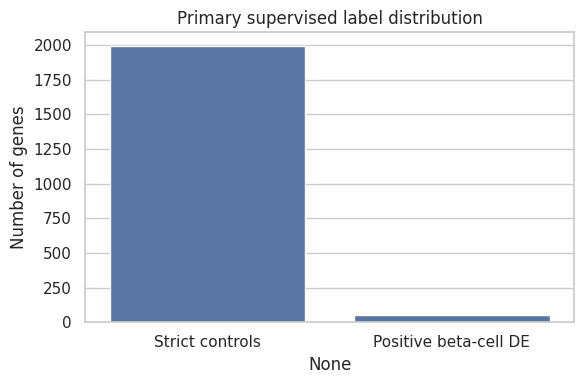

In [ ]:
#@title 15. Figure helper
def savefig(name, dpi=300):
    plt.tight_layout()
    plt.savefig(FIG/f"{name}.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(FIG/f"{name}.svg", bbox_inches="tight")
    plt.show()

# Class balance
plt.figure(figsize=(6,4))
counts = pd.Series({"Strict controls": int((y==0).sum()), "Positive beta-cell DE": int((y==1).sum())})
sns.barplot(x=counts.index, y=counts.values)
plt.ylabel("Number of genes")
plt.title("Primary supervised label distribution")
savefig("01_label_distribution")


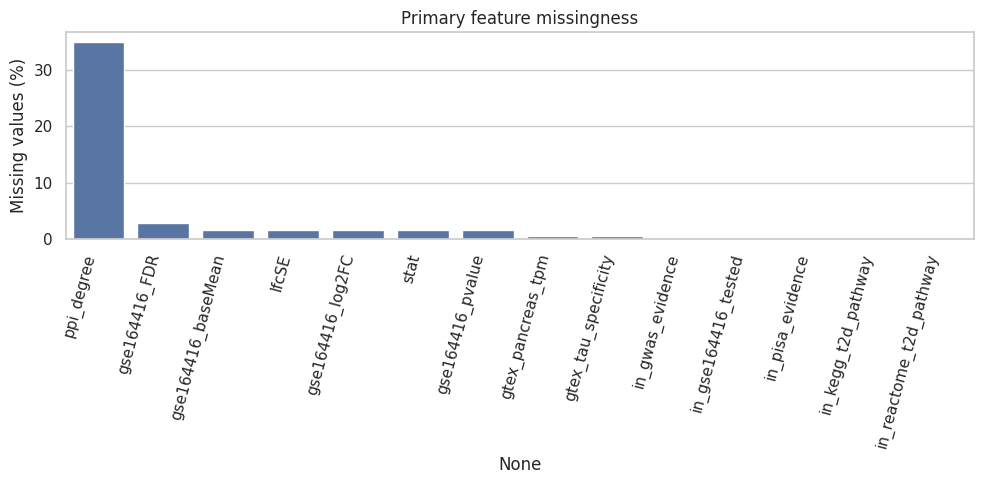

In [ ]:
#@title 16. Missingness visualization
missing_pct = X.isna().mean().sort_values(ascending=False)
plt.figure(figsize=(10,5))
sns.barplot(x=missing_pct.index, y=100*missing_pct.values)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Missing values (%)")
plt.title("Primary feature missingness")
savefig("02_feature_missingness")

missing_pct.rename("missing_fraction").to_csv(TAB/"feature_missingness.csv")


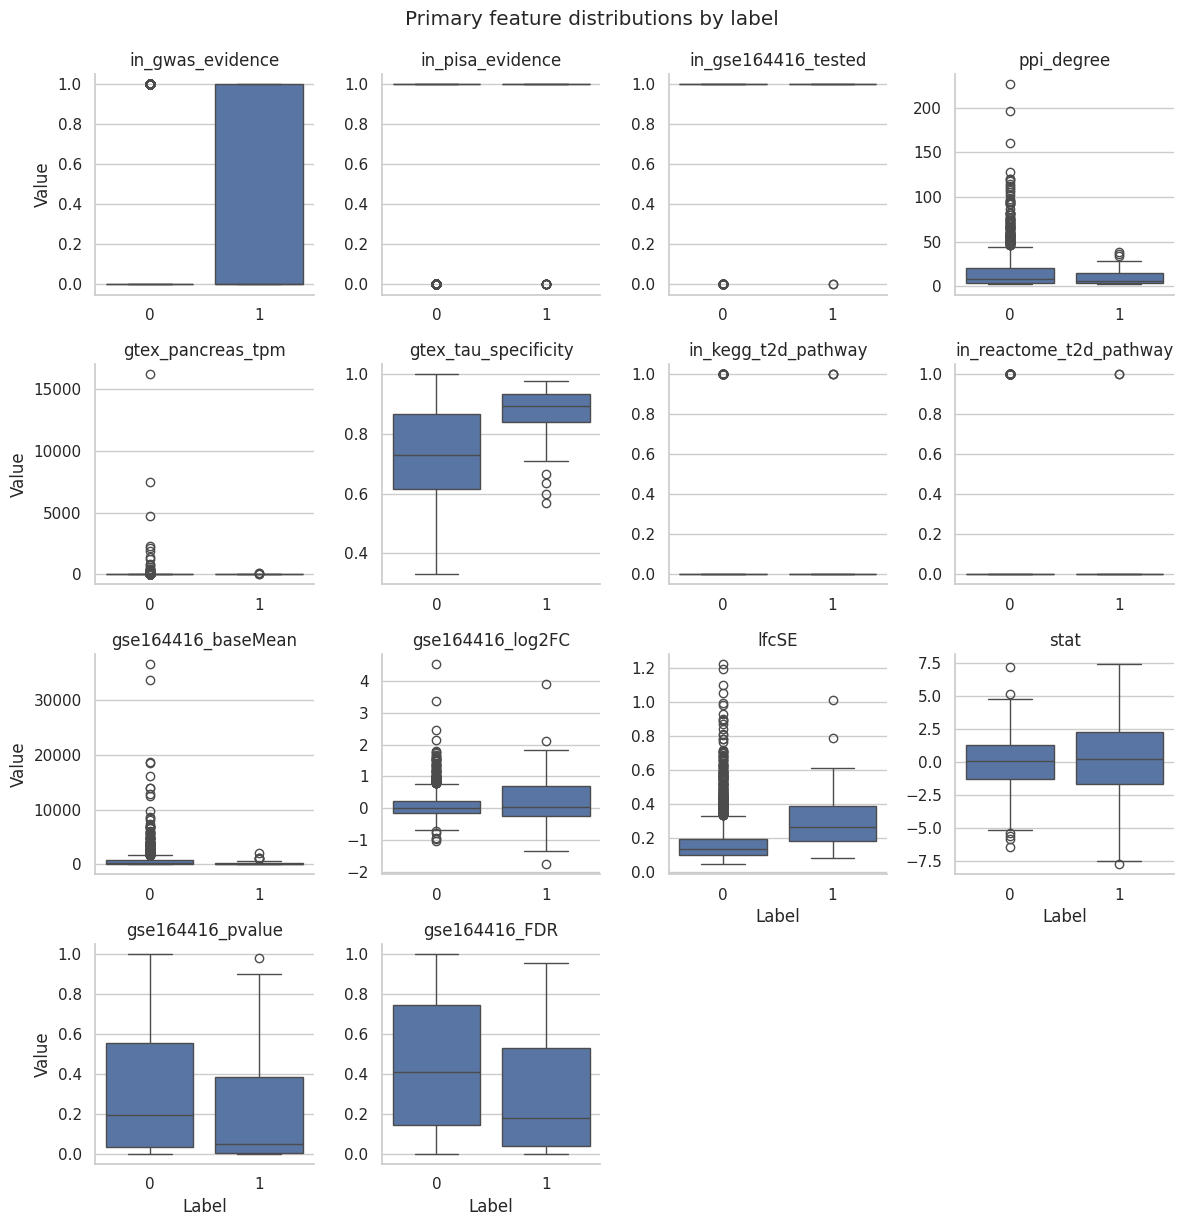

In [ ]:
#@title 17. Feature distributions by class
long_parts = []
for f in PRIMARY_FEATURES:
    z = pd.DataFrame({"value": pd.to_numeric(X[f], errors="coerce"), "label": y.values})
    z["feature"] = f
    long_parts.append(z)
dist_df = pd.concat(long_parts, ignore_index=True)

# Robustly cap only for visualization, never for training.
g = sns.FacetGrid(dist_df, col="feature", col_wrap=4, sharex=False, sharey=False, height=3)
g.map_dataframe(sns.boxplot, x="label", y="value")
g.set_titles("{col_name}")
g.set_xlabels("Label")
g.set_ylabels("Value")
plt.suptitle("Primary feature distributions by label", y=1.02)
plt.savefig(FIG/"03_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG/"03_feature_distributions.svg", bbox_inches="tight")
plt.show()


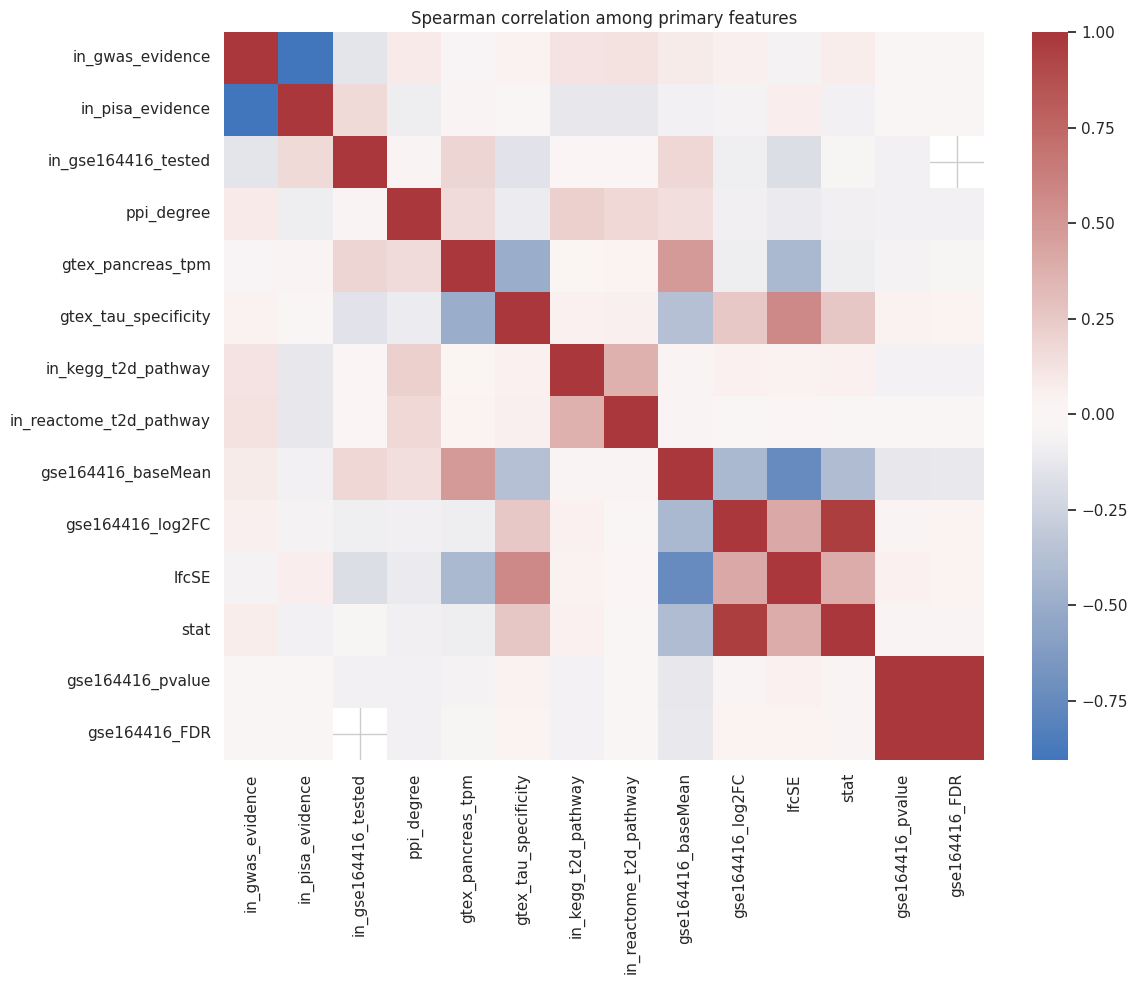

In [ ]:
#@title 18. Correlation heatmap
corr = X.apply(pd.to_numeric, errors="coerce").corr(method="spearman")
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="vlag", center=0, square=False)
plt.title("Spearman correlation among primary features")
savefig("04_feature_correlation")
corr.to_csv(TAB/"primary_feature_spearman_correlation.csv")


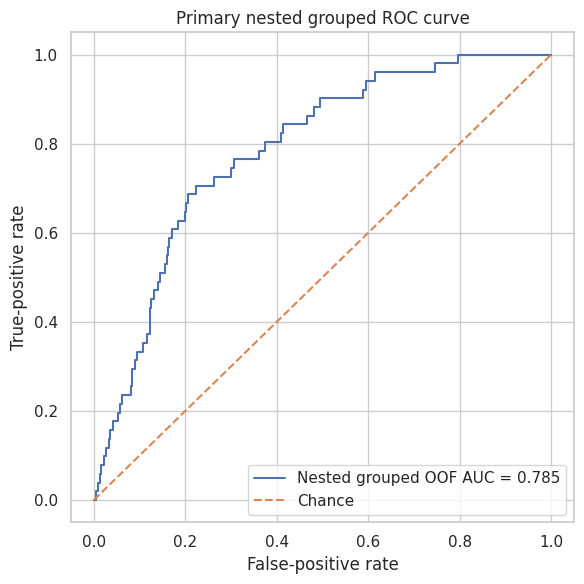

In [ ]:
#@title 19. ROC curve
fpr, tpr, _ = roc_curve(y, oof)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"Nested grouped OOF AUC = {roc_auc_score(y,oof):.3f}")
plt.plot([0,1],[0,1],"--", label="Chance")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Primary nested grouped ROC curve")
plt.legend()
savefig("05_primary_roc")


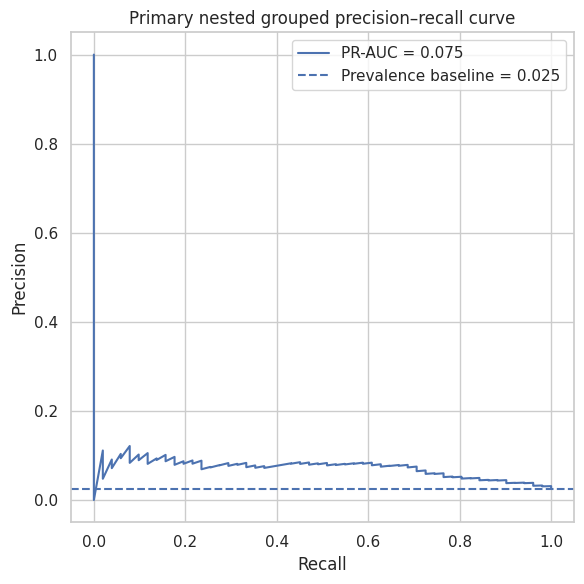

In [ ]:
#@title 20. Precision–recall curve
precision, recall, _ = precision_recall_curve(y, oof)
baseline = y.mean()
plt.figure(figsize=(6,6))
plt.plot(recall, precision, label=f"PR-AUC = {average_precision_score(y,oof):.3f}")
plt.axhline(baseline, linestyle="--", label=f"Prevalence baseline = {baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Primary nested grouped precision–recall curve")
plt.legend()
savefig("06_primary_pr")


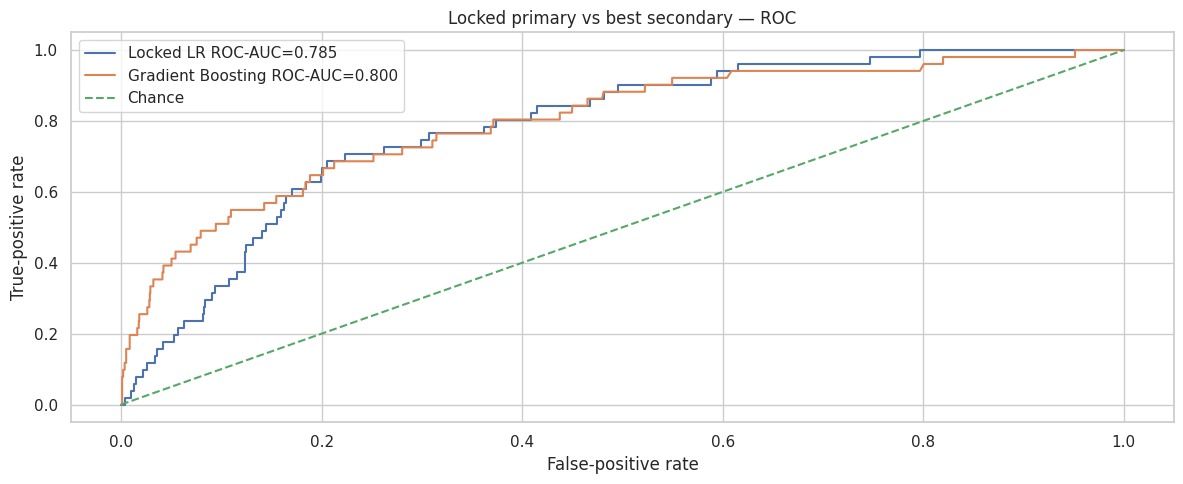

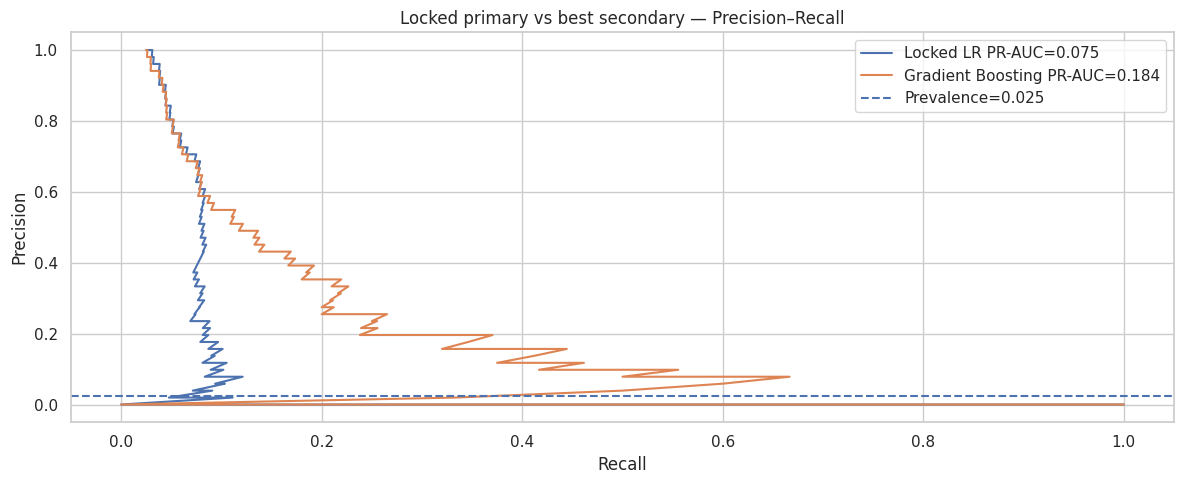

In [ ]:
#@title 20B. Primary vs best-secondary ROC and PR curves
secondary_p=benchmark_oof[secondary_name]
fig,ax=plt.subplots(figsize=(12,5))
# ROC
fpr1,tpr1,_=roc_curve(y,oof)
fpr2,tpr2,_=roc_curve(y,secondary_p)
ax.plot(fpr1,tpr1,label=f"Locked LR ROC-AUC={roc_auc_score(y,oof):.3f}")
ax.plot(fpr2,tpr2,label=f"{secondary_name} ROC-AUC={roc_auc_score(y,secondary_p):.3f}")
ax.plot([0,1],[0,1],"--",label="Chance")
ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title("Locked primary vs best secondary — ROC")
ax.legend(); plt.tight_layout(); savefig("06B_primary_vs_secondary_roc")

fig,ax=plt.subplots(figsize=(12,5))
r1,p1,_=precision_recall_curve(y,oof)
r2,p2,_=precision_recall_curve(y,secondary_p)
ax.plot(r1,p1,label=f"Locked LR PR-AUC={average_precision_score(y,oof):.3f}")
ax.plot(r2,p2,label=f"{secondary_name} PR-AUC={average_precision_score(y,secondary_p):.3f}")
ax.axhline(y.mean(),ls="--",label=f"Prevalence={y.mean():.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Locked primary vs best secondary — Precision–Recall")
ax.legend(); plt.tight_layout(); savefig("06B_primary_vs_secondary_pr")


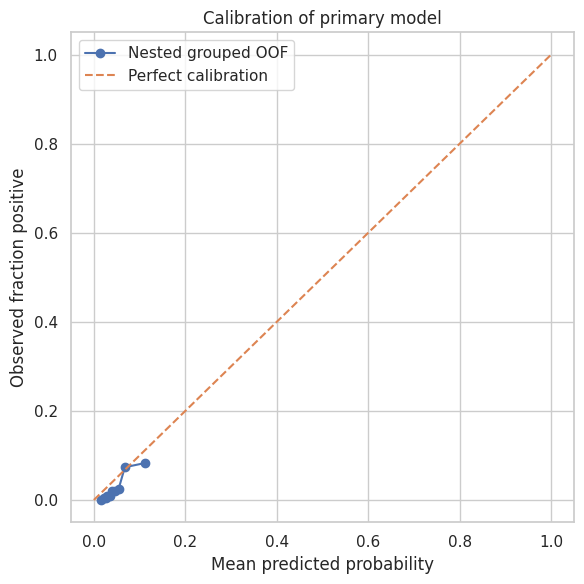

In [ ]:
#@title 21. Calibration curve
prob_true, prob_pred = calibration_curve(y, oof, n_bins=10, strategy="quantile")
plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker="o", label="Nested grouped OOF")
plt.plot([0,1],[0,1],"--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction positive")
plt.title("Calibration of primary model")
plt.legend()
savefig("07_calibration")


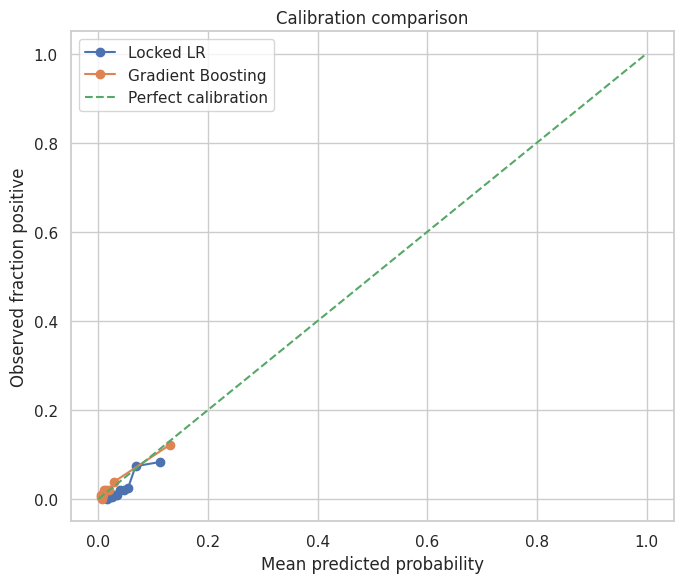

In [ ]:
#@title 21B. Calibration comparison — primary vs best secondary
fig,ax=plt.subplots(figsize=(7,6))
for name,p in [("Locked LR",oof),(secondary_name,secondary_p)]:
    pt,pp=calibration_curve(y,p,n_bins=10,strategy="quantile")
    ax.plot(pp,pt,marker="o",label=name)
ax.plot([0,1],[0,1],"--",label="Perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction positive")
ax.set_title("Calibration comparison")
ax.legend(); plt.tight_layout(); savefig("07B_calibration_comparison")


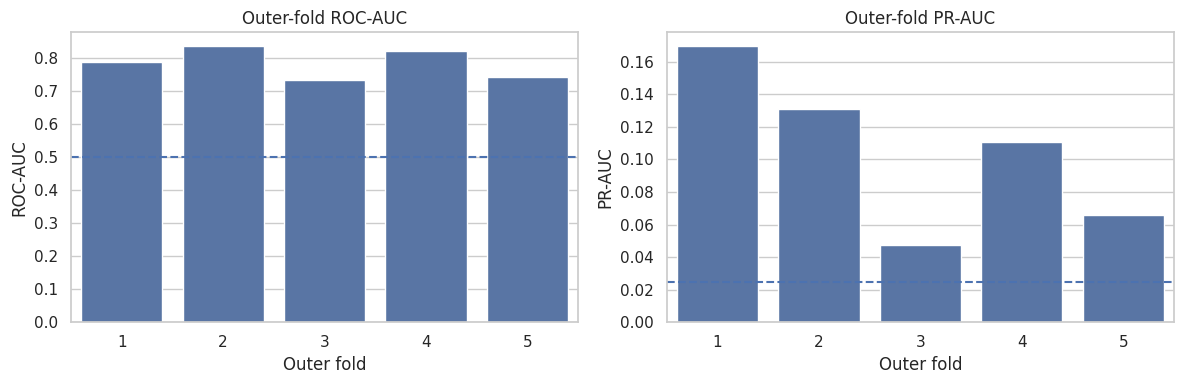

In [ ]:
#@title 22. Fold-wise ROC / PR performance
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=nested_folds, x="fold", y="roc_auc", ax=ax[0])
ax[0].axhline(0.5, ls="--")
ax[0].set_title("Outer-fold ROC-AUC")
ax[0].set_xlabel("Outer fold")
ax[0].set_ylabel("ROC-AUC")

sns.barplot(data=nested_folds, x="fold", y="pr_auc", ax=ax[1])
ax[1].axhline(y.mean(), ls="--")
ax[1].set_title("Outer-fold PR-AUC")
ax[1].set_xlabel("Outer fold")
ax[1].set_ylabel("PR-AUC")
plt.tight_layout()
plt.savefig(FIG/"08_fold_performance.png",dpi=300,bbox_inches="tight")
plt.savefig(FIG/"08_fold_performance.svg",bbox_inches="tight")
plt.show()


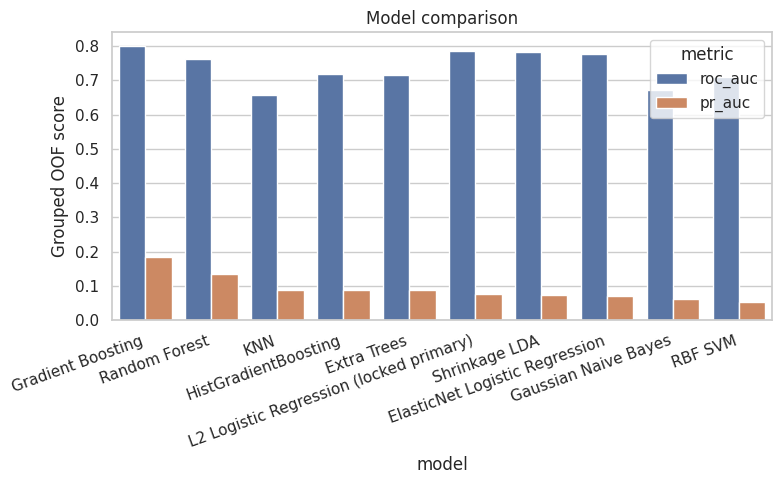

In [ ]:
#@title 23. Model comparison figure
plt.figure(figsize=(8,5))
mc = model_comparison.melt(id_vars="model", value_vars=["roc_auc","pr_auc"], var_name="metric", value_name="score")
sns.barplot(data=mc, x="model", y="score", hue="metric")
plt.xticks(rotation=20, ha="right")
plt.ylabel("Grouped OOF score")
plt.title("Model comparison")
savefig("09_model_comparison")


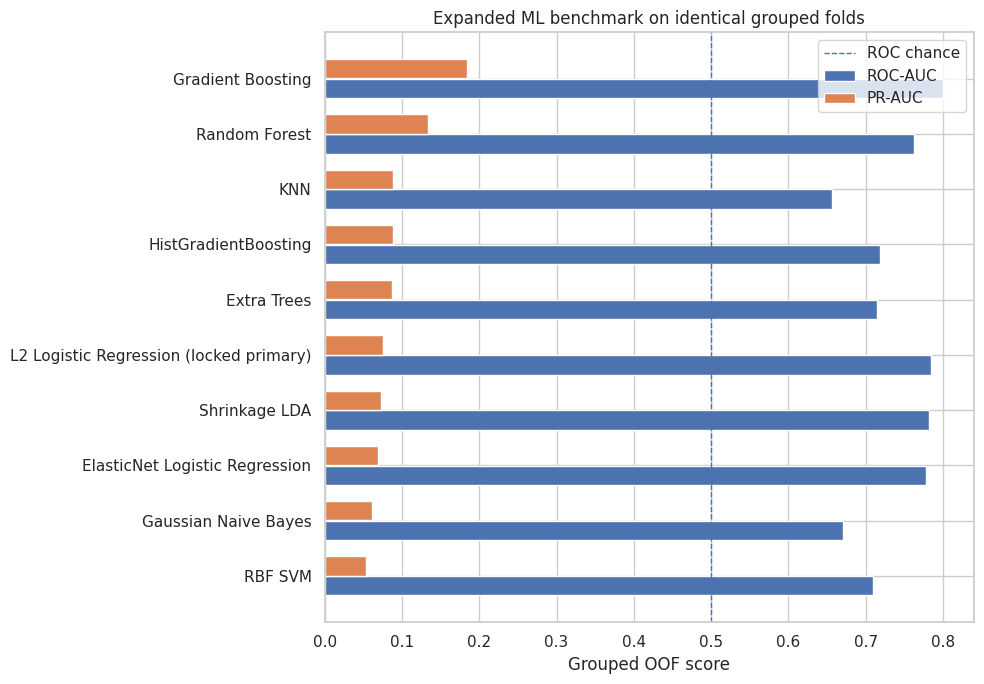

In [ ]:
#@title 23B. Expanded model benchmark figure
plot_df=model_comparison.sort_values("pr_auc",ascending=True).copy()
fig,ax=plt.subplots(figsize=(10,7))
ypos=np.arange(len(plot_df))
ax.barh(ypos-0.18,plot_df["roc_auc"],height=0.35,label="ROC-AUC")
ax.barh(ypos+0.18,plot_df["pr_auc"],height=0.35,label="PR-AUC")
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df["model"])
ax.axvline(0.5,ls="--",linewidth=1,label="ROC chance")
ax.set_xlabel("Grouped OOF score")
ax.set_title("Expanded ML benchmark on identical grouped folds")
ax.legend()
plt.tight_layout()
savefig("09B_expanded_model_benchmark")


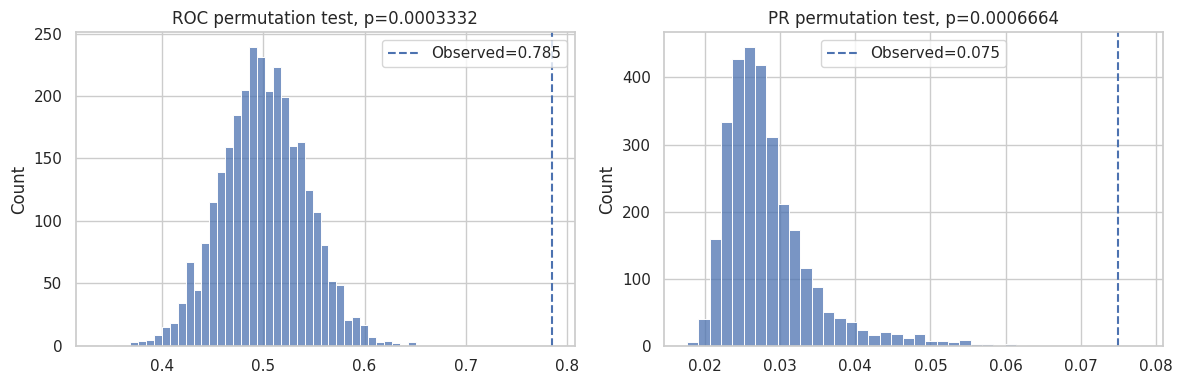

In [ ]:
#@title 24. Permutation null distributions
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.histplot(roc_null, bins=40, ax=ax[0])
ax[0].axvline(roc_obs, ls="--", label=f"Observed={roc_obs:.3f}")
ax[0].set_title(f"ROC permutation test, p={roc_p:.4g}")
ax[0].legend()

sns.histplot(pr_null, bins=40, ax=ax[1])
ax[1].axvline(pr_obs, ls="--", label=f"Observed={pr_obs:.3f}")
ax[1].set_title(f"PR permutation test, p={pr_p:.4g}")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG/"10_permutation_tests.png",dpi=300,bbox_inches="tight")
plt.savefig(FIG/"10_permutation_tests.svg",bbox_inches="tight")
plt.show()


,rank,feature,coefficient,abs_coefficient,direction
0,1,gtex_tau_specificity,0.387297,0.387297,positive
1,2,gse164416_FDR,-0.289886,0.289886,negative
2,3,lfcSE,0.252946,0.252946,positive
3,4,in_gwas_evidence,0.225626,0.225626,positive
4,5,stat,-0.174451,0.174451,negative
5,6,gse164416_baseMean,-0.150327,0.150327,negative
6,7,ppi_degree,-0.141303,0.141303,negative
7,8,in_gse164416_tested,0.113786,0.113786,positive
8,9,in_pisa_evidence,0.110493,0.110493,positive
9,10,in_kegg_t2d_pathway,0.109552,0.109552,positive


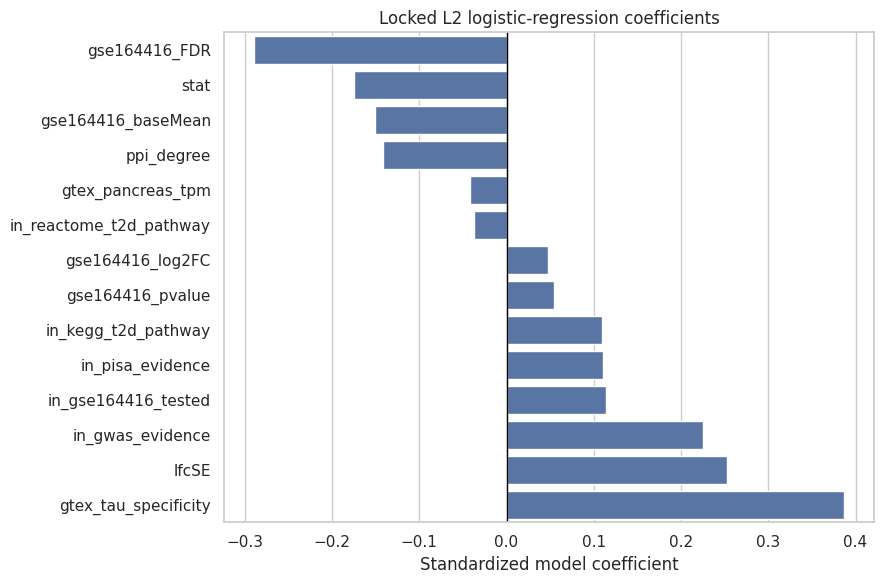

Coefficient count: 14
Feature count: 14
CELL 25: PASS


In [ ]:
#@title 25. Fit locked primary full labeled model for interpretation / prioritization
# The final gene-level prioritization score remains the prespecified v10 LR, C=0.1.
# Imputation does NOT add indicator columns: exactly 14 model coefficients correspond
# to exactly the 14 locked biological/statistical predictors.

final_model = make_lr(C=PRIMARY_C)
final_model.fit(X, y)

lr_core = final_model.named_steps["model"]
coef = np.asarray(lr_core.coef_).reshape(-1)

assert len(coef) == len(PRIMARY_FEATURES), (
    f"Coefficient mismatch: {len(coef)} coefficients for {len(PRIMARY_FEATURES)} features."
)

feature_importance = pd.DataFrame({
    "feature": PRIMARY_FEATURES,
    "coefficient": coef,
    "abs_coefficient": np.abs(coef),
})
feature_importance["direction"] = np.where(
    feature_importance["coefficient"] > 0, "positive",
    np.where(feature_importance["coefficient"] < 0, "negative", "zero")
)
feature_importance = feature_importance.sort_values(
    "abs_coefficient", ascending=False
).reset_index(drop=True)
feature_importance.insert(0, "rank", np.arange(1, len(feature_importance)+1))

display(feature_importance)
feature_importance.to_csv(TAB/"locked_lr_coefficients.csv", index=False)

plt.figure(figsize=(9,6))
tmp = feature_importance.sort_values("coefficient")
sns.barplot(data=tmp, y="feature", x="coefficient")
plt.axvline(0, color="black", lw=1)
plt.title("Locked L2 logistic-regression coefficients")
plt.xlabel("Standardized model coefficient")
plt.ylabel("")
savefig("11_feature_coefficients")

print("Coefficient count:", len(coef))
print("Feature count:", len(PRIMARY_FEATURES))
print("CELL 25: PASS")


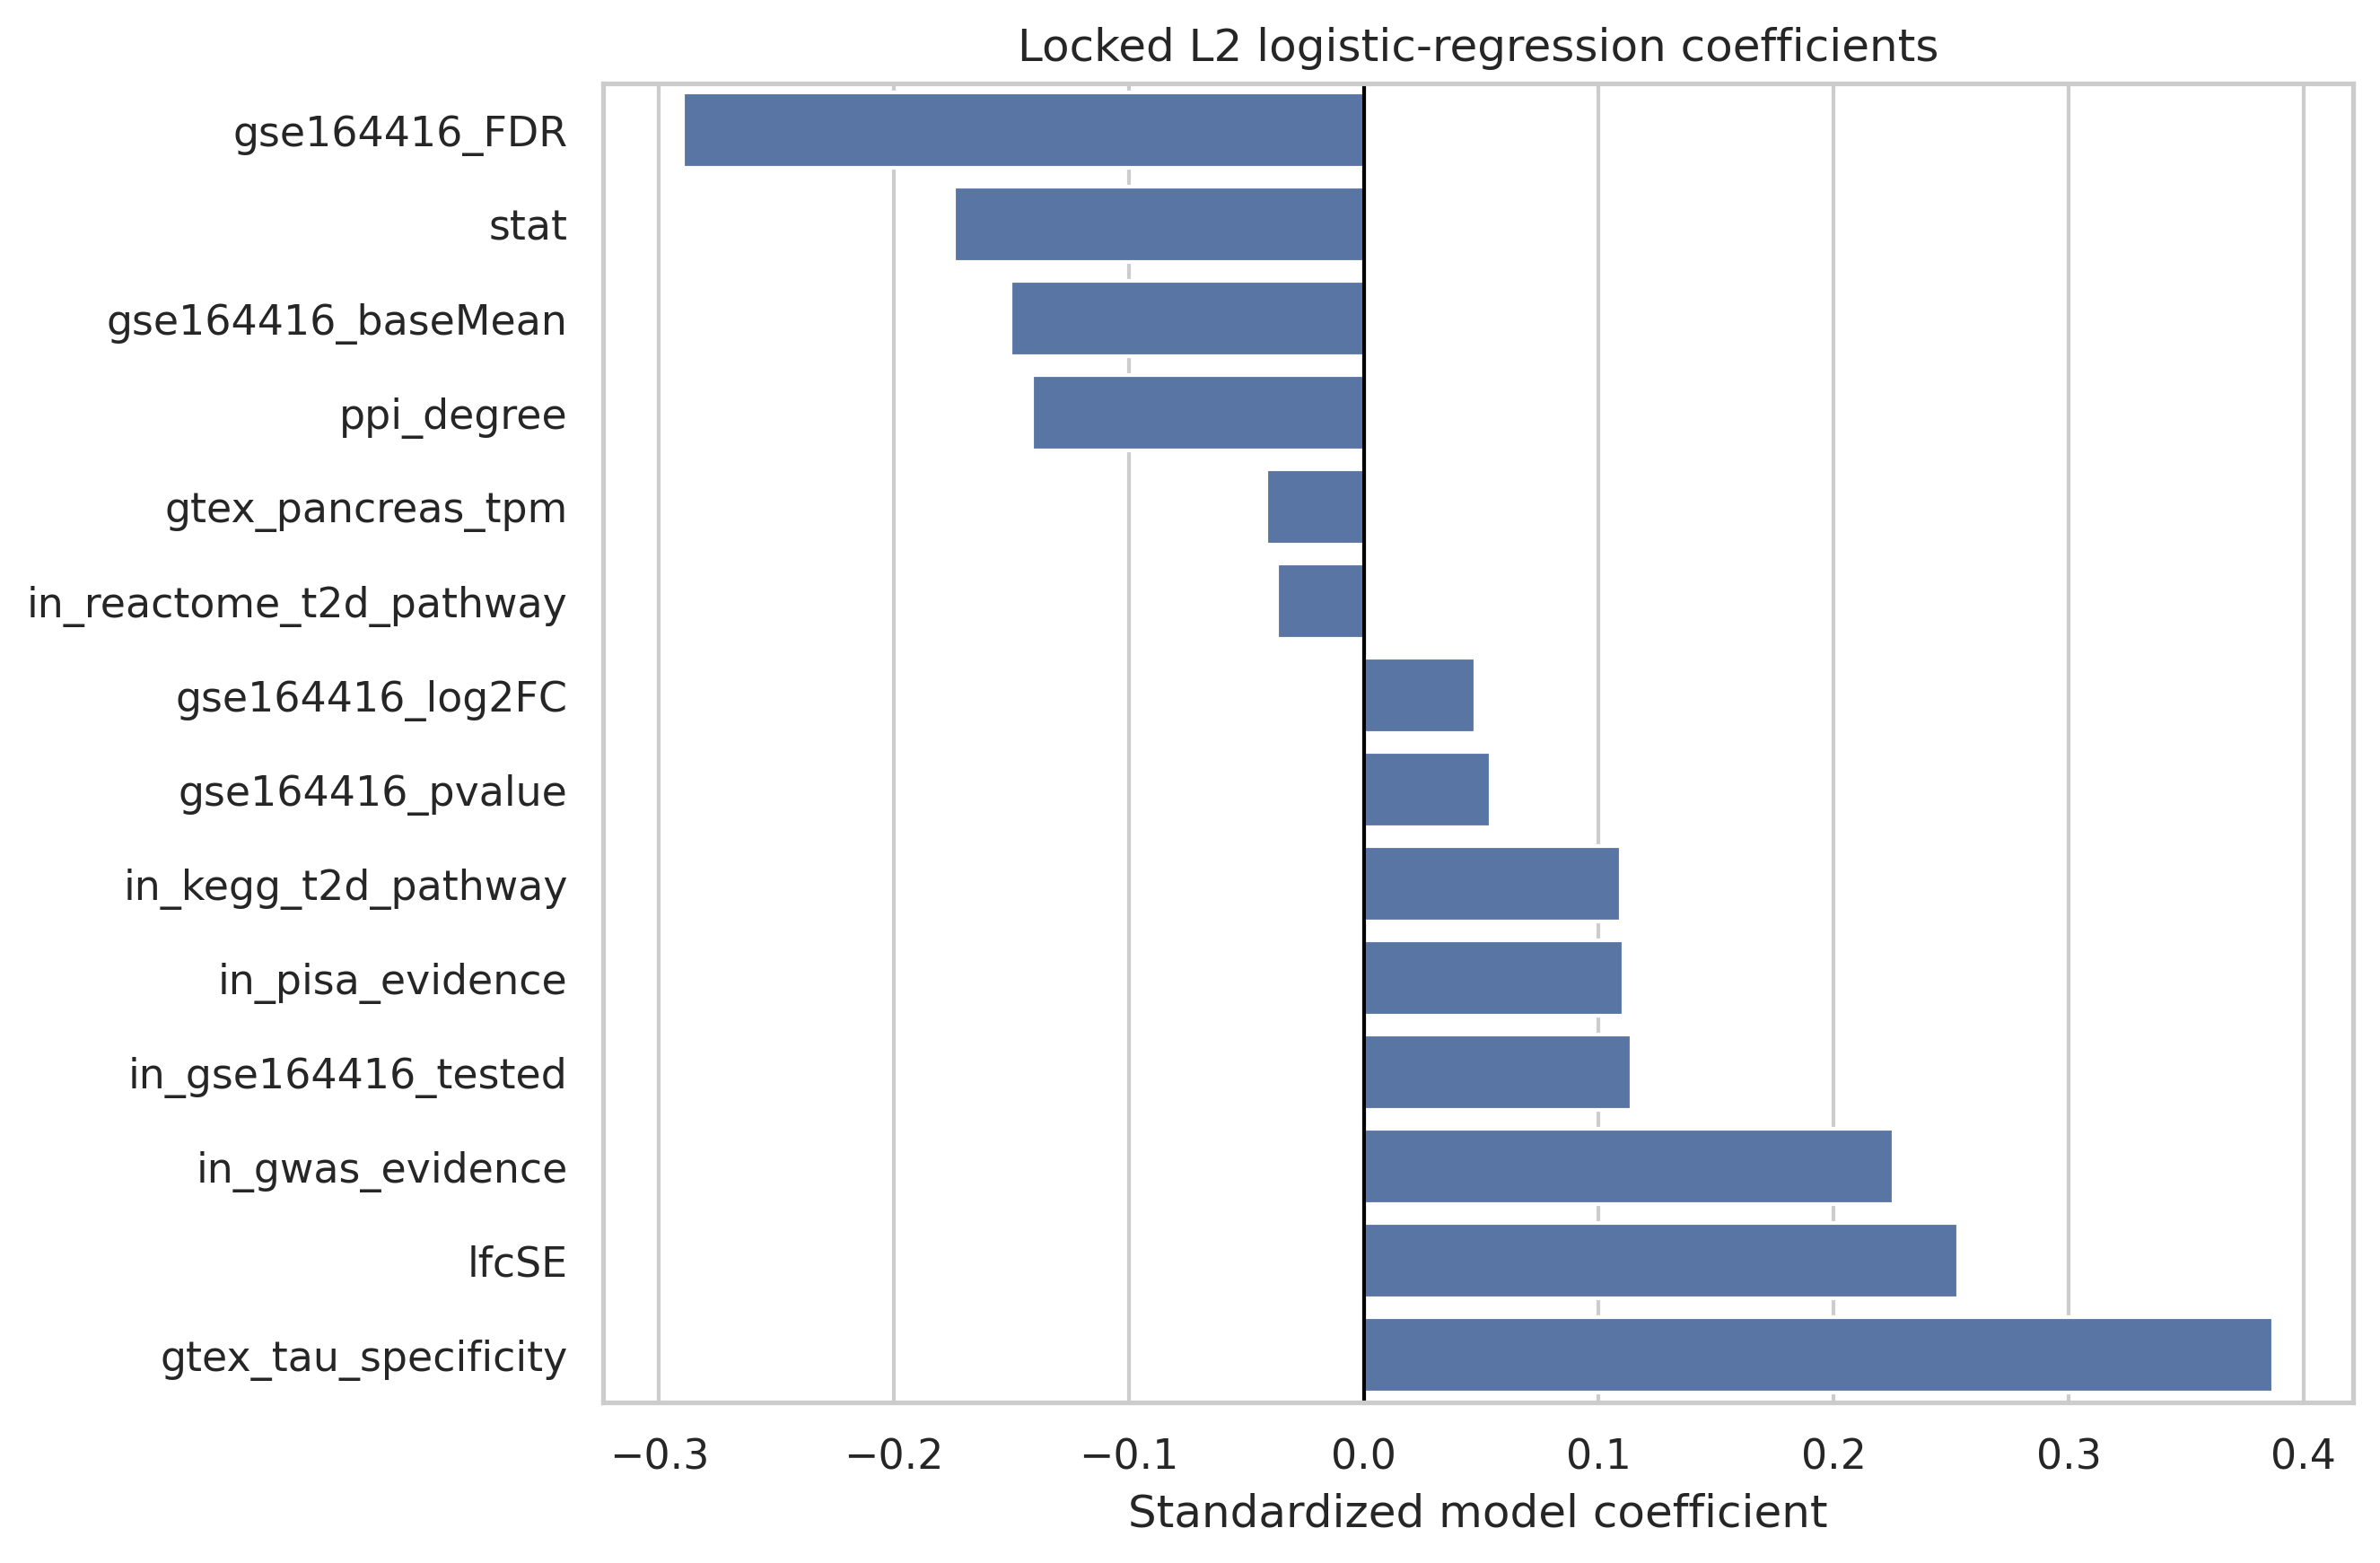

In [ ]:
from IPython.display import Image, display
# Display the saved feature coefficients figure
display(Image(filename='/content/v10_ml_outputs/figures/11_feature_coefficients.png'))

,feature,mean_delta_pr,median_delta_pr,sd_delta_pr,mean_delta_roc
11,lfcSE,0.037405,0.028107,0.026619,0.055688
5,gtex_tau_specificity,0.025115,0.016278,0.041448,0.113130
9,in_pisa_evidence,0.015056,0.008527,0.019771,-0.005543
13,stat,0.012413,0.009094,0.017787,0.033250
6,in_gse164416_tested,0.009987,0.013001,0.009301,-0.001310
1,gse164416_baseMean,0.006280,0.004446,0.007402,0.004192
12,ppi_degree,0.004906,0.005017,0.003119,0.000780
4,gtex_pancreas_tpm,0.000602,0.000000,0.001298,-0.000045
3,gse164416_pvalue,0.000138,0.001226,0.002995,0.004297
10,in_reactome_t2d_pathway,-0.005078,0.001739,0.015907,0.000177


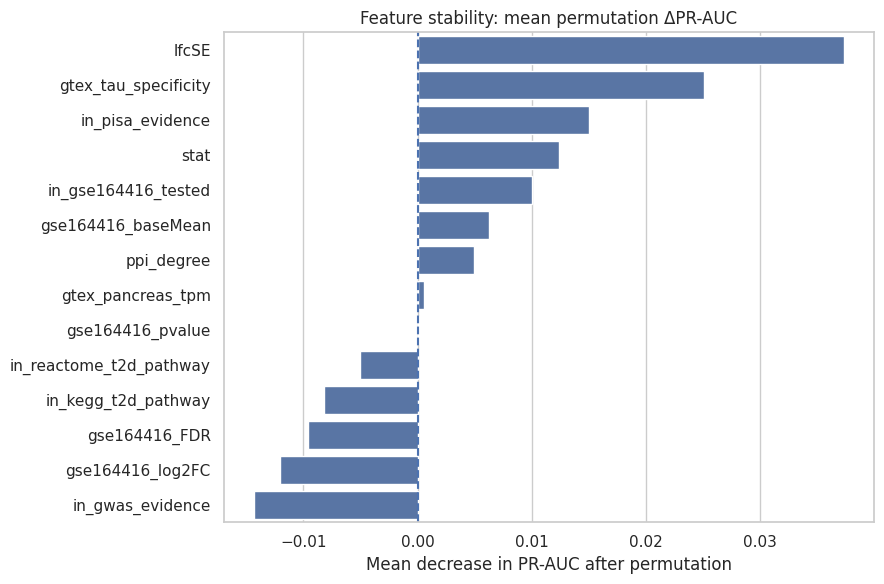

In [ ]:
#@title 26. Fold-wise permutation feature stability
# Each outer fold computes permutation delta ROC/PR on held-out data.
stab_rows = []
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (tr, te) in enumerate(outer.split(X, y, groups), 1):
    m = make_lr(C=0.1)
    m.fit(X.iloc[tr], y.iloc[tr])
    base_p = m.predict_proba(X.iloc[te])[:,1]
    base_pr = average_precision_score(y.iloc[te], base_p)
    base_roc = roc_auc_score(y.iloc[te], base_p)

    rng = np.random.default_rng(SEED + fold)
    for j, f in enumerate(PRIMARY_FEATURES):
        Xp = X.iloc[te].copy()
        vals = Xp[f].to_numpy().copy()
        rng.shuffle(vals)
        Xp[f] = vals
        pp = m.predict_proba(Xp)[:,1]
        stab_rows.append({
            "fold":fold,
            "feature":f,
            "delta_pr_auc":base_pr-average_precision_score(y.iloc[te],pp),
            "delta_roc_auc":base_roc-roc_auc_score(y.iloc[te],pp)
        })

stability = pd.DataFrame(stab_rows)
stability_summary = stability.groupby("feature").agg(
    mean_delta_pr=("delta_pr_auc","mean"),
    median_delta_pr=("delta_pr_auc","median"),
    sd_delta_pr=("delta_pr_auc","std"),
    mean_delta_roc=("delta_roc_auc","mean")
).reset_index().sort_values("mean_delta_pr",ascending=False)

display(stability_summary)
stability.to_csv(TAB/"feature_stability_by_fold.csv",index=False)
stability_summary.to_csv(TAB/"feature_stability_summary.csv",index=False)

plt.figure(figsize=(9,6))
sns.barplot(data=stability_summary.head(14), y="feature", x="mean_delta_pr")
plt.axvline(0,ls="--")
plt.title("Feature stability: mean permutation ΔPR-AUC")
plt.xlabel("Mean decrease in PR-AUC after permutation")
plt.ylabel("")
savefig("12_feature_stability")


,PISA_gene_id,gene_symbol,v10_locked_LR_score,v10_locked_LR_rank,label
1197,NaN,ENSG00000256417,0.499814,1,NaN
853,NaN,ENSG00000225028,0.344177,2,NaN
2112,NaN,LEP,0.340238,3,NaN
3743,NaN,ZAN,0.325643,4,NaN
2652,NaN,PIP,0.294408,5,NaN
421,NaN,CD177,0.282247,6,NaN
1698,NaN,FCRLA,0.277079,7,NaN
435,NaN,CDH7,0.264870,8,NaN
3644,NaN,UGT2B11,0.261905,9,0.0
3207,NaN,SLC6A14,0.256948,10,0.0


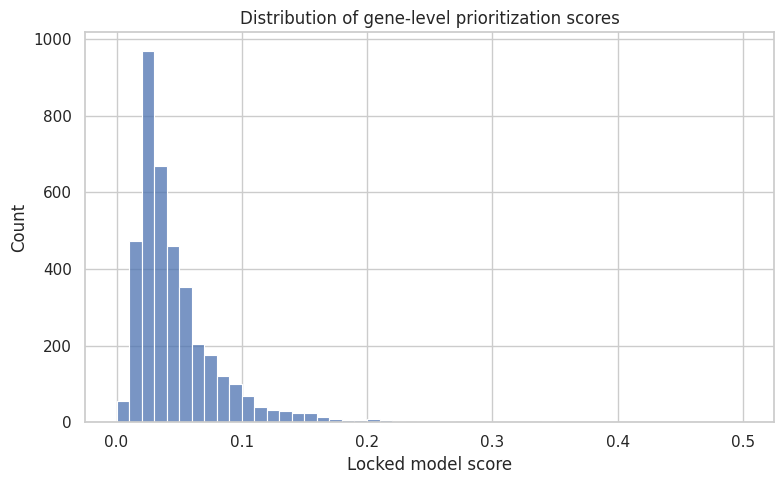

In [ ]:
#@title 27. Gene-level locked score and ranking
all_X = df[PRIMARY_FEATURES].copy()
df_scores = df.copy()
df_scores["v10_locked_LR_score"] = final_model.predict_proba(all_X)[:,1]
df_scores["v10_locked_LR_rank"] = (
    df_scores["v10_locked_LR_score"].rank(method="min", ascending=False).astype(int)
)

score_cols = [c for c in [
    "PISA_gene_id","gene_id","gene_symbol","symbol","gene",
    "v10_locked_LR_score","v10_locked_LR_rank",target_col
] if c in df_scores.columns]

top_genes = df_scores.sort_values("v10_locked_LR_score",ascending=False).head(100)[score_cols]
display(top_genes.head(30))

top_genes.to_csv(TAB/"top100_gene_prioritization.csv",index=False)
df_scores[score_cols].to_csv(TAB/"all_gene_scores.csv",index=False)

plt.figure(figsize=(8,5))
sns.histplot(df_scores["v10_locked_LR_score"], bins=50)
plt.xlabel("Locked model score")
plt.title("Distribution of gene-level prioritization scores")
savefig("13_gene_score_distribution")


In [ ]:
#@title 27B. Secondary-model gene ranking (exploratory)
# Fit the best secondary model on all labeled genes only after its benchmark is complete.
# This ranking is exploratory and is never used to define the primary target or performance.
secondary_full_model=clone(BENCHMARK_MODELS[secondary_name])
secondary_full_model.fit(X,y)
df_scores["v10_secondary_model_score"]=secondary_full_model.predict_proba(all_X)[:,1]
df_scores["v10_secondary_model_rank"]=df_scores["v10_secondary_model_score"].rank(method="min",ascending=False).astype(int)
secondary_top=df_scores.sort_values("v10_secondary_model_score",ascending=False).head(100)[score_cols+["v10_secondary_model_score","v10_secondary_model_rank"]]
secondary_top.to_csv(TAB/"top100_best_secondary_model_prioritization.csv",index=False)
print("Exploratory secondary ranking model:",secondary_name)
display(secondary_top.head(30))


Exploratory secondary ranking model: Gradient Boosting


,PISA_gene_id,gene_symbol,v10_locked_LR_score,v10_locked_LR_rank,label,v10_secondary_model_score,v10_secondary_model_rank
2585,NaN,PCOLCE2,0.105393,253,1.0,0.801219,1
1640,NaN,FAIM2,0.116472,192,1.0,0.762526,2
2614,NaN,PENK,0.252111,11,NaN,0.716239,3
3179,NaN,SLC2A2,0.228725,17,1.0,0.703861,4
3601,NaN,TTBK1,0.075822,576,1.0,0.689186,5
2851,NaN,RASGRP1,0.147926,100,NaN,0.687356,6
1769,NaN,GAD1,0.167673,59,1.0,0.665214,7
2610,NaN,PDZRN4,0.090351,386,NaN,0.659839,8
339,NaN,C6orf58,0.160716,67,NaN,0.659797,9
71,NaN,ADGRB3,0.076749,561,1.0,0.649698,10


,k,hits,precision,baseline,enrichment
0,10,2,0.200,0.024976,8.007843
1,20,4,0.200,0.024976,8.007843
2,40,5,0.125,0.024976,5.004902
3,50,8,0.160,0.024976,6.406275
4,100,14,0.140,0.024976,5.605490
5,200,22,0.110,0.024976,4.404314
6,500,38,0.076,0.024976,3.042980


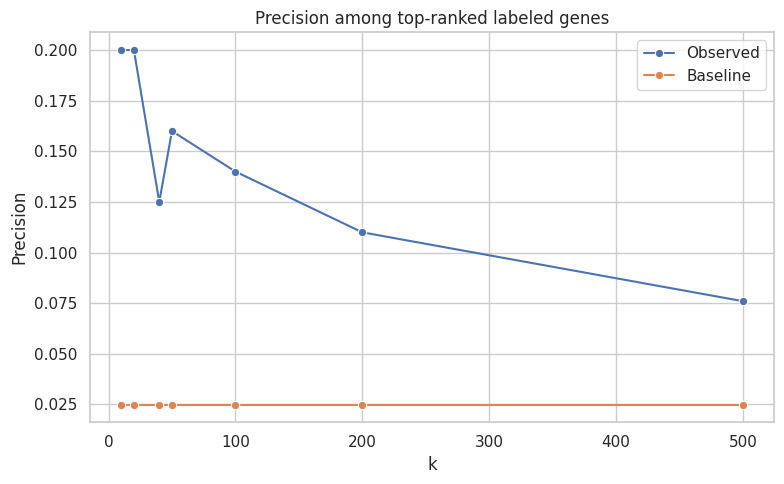

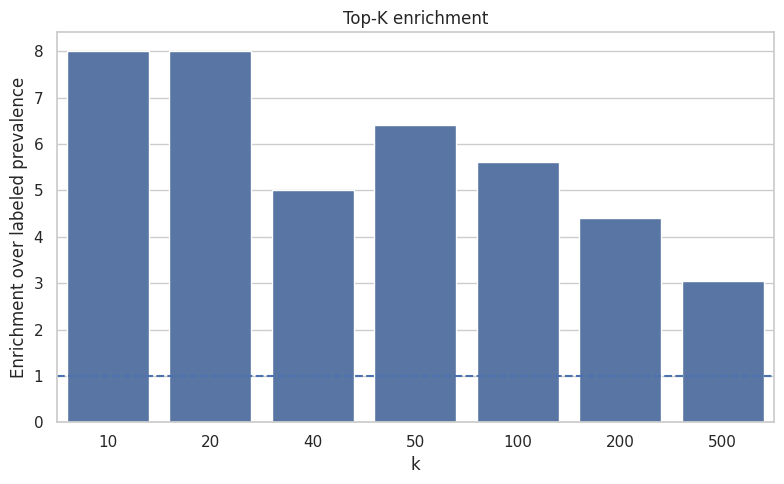

In [ ]:
#@title 28. Precision@K and enrichment among labeled genes
labeled_scores = df_scores.loc[labeled.index[labeled], ["v10_locked_LR_score"]].copy()
labeled_scores["y"] = y.values
labeled_scores = labeled_scores.sort_values("v10_locked_LR_score",ascending=False)

ks = [10,20,40,50,100,200,500]
rows=[]
baseline = y.mean()
for k in ks:
    hit = labeled_scores.head(min(k,len(labeled_scores)))["y"].sum()
    precision_k = hit/min(k,len(labeled_scores))
    rows.append({
        "k":k,
        "hits":int(hit),
        "precision":precision_k,
        "baseline":baseline,
        "enrichment":precision_k/baseline if baseline>0 else np.nan
    })
p_at_k = pd.DataFrame(rows)
display(p_at_k)
p_at_k.to_csv(TAB/"precision_at_k.csv",index=False)

plt.figure(figsize=(8,5))
sns.lineplot(data=p_at_k,x="k",y="precision",marker="o",label="Observed")
sns.lineplot(data=p_at_k,x="k",y="baseline",marker="o",label="Baseline")
plt.ylabel("Precision")
plt.title("Precision among top-ranked labeled genes")
savefig("14_precision_at_k")

plt.figure(figsize=(8,5))
sns.barplot(data=p_at_k,x="k",y="enrichment")
plt.axhline(1,ls="--")
plt.ylabel("Enrichment over labeled prevalence")
plt.title("Top-K enrichment")
savefig("15_topk_enrichment")


# 29. Locked independent GSE164416 evaluation

For the external evaluation, **every GSE164416-derived predictor is removed**. The model is trained using the non-GSE164416 subset of the primary feature set, preserving the external lock.

The workbook already records the locked external result. This cell attempts to reproduce it if an explicit external target/score table is available in the workbook; otherwise it reports the locked result from the artifact without inventing new labels.


In [ ]:
#@title 30. External GSE164416 reproduction when explicit columns are available
external_candidates = [c for c in df.columns if "gse164416" in str(c).lower()]
print("GSE164416-related columns:", external_candidates)

external_feature_cols = [
    c for c in PRIMARY_FEATURES
    if "gse164416" not in c.lower()
]
print("Non-GSE164416 features retained for external model:", external_feature_cols)

# Search for an explicit external binary label.
external_label_candidates = [
    c for c in df.columns
    if any(k in str(c).lower() for k in [
        "gse164416_label", "gse164416_de", "external_label"
    ])
]
print("External label candidates:", external_label_candidates)

external_result = {
    "status": "locked_artifact_only",
    "roc_auc": 0.5655391292634221,
    "pr_auc": 0.2165690454666739,
    "brier": 0.1968833176964403,
    "n_genes": 2224,
    "positives": 363,
    "controls": 1861
}

if external_label_candidates:
    ext_label = external_label_candidates[0]
    ext_mask = df[ext_label].map(normalize_label).notna()
    if ext_mask.sum() > 50:
        Xe = df.loc[ext_mask, external_feature_cols].copy()
        ye = df.loc[ext_mask, ext_label].map(normalize_label).astype(int)
        ext_model = make_lr(C=0.1)
        ext_model.fit(X.loc[:, external_feature_cols], y)
        pe = ext_model.predict_proba(Xe)[:,1]
        external_result = {
            "status":"reproduced_from_workbook",
            "roc_auc":roc_auc_score(ye,pe),
            "pr_auc":average_precision_score(ye,pe),
            "brier":safe_brier(ye,pe),
            "n_genes":len(ye),
            "positives":int(ye.sum()),
            "controls":int((ye==0).sum())
        }

display(pd.DataFrame([external_result]))
pd.DataFrame([external_result]).to_csv(TAB/"external_gse164416_summary.csv",index=False)


GSE164416-related columns: ['gse164416_baseMean', 'gse164416_log2FC', 'gse164416_pvalue', 'gse164416_FDR', 'gse164416_n_donors_ND', 'gse164416_n_donors_T2D', 'gse164416_low_powered_flag', 'gse164416_small_n_flag', 'gse164416_t3cd_excluded', 'gse164416_igt_excluded', 'gse164416_source', 'in_gse164416_tested', 'GSE164416_validation_role', 'GSE164416_validation_role_v6']
Non-GSE164416 features retained for external model: ['in_gwas_evidence', 'in_pisa_evidence', 'ppi_degree', 'gtex_pancreas_tpm', 'gtex_tau_specificity', 'in_kegg_t2d_pathway', 'in_reactome_t2d_pathway', 'lfcSE', 'stat']
External label candidates: []


,status,roc_auc,pr_auc,brier,n_genes,positives,controls
0,locked_artifact_only,0.565539,0.216569,0.196883,2224,363,1861


In [ ]:
#@title 31. Reproducibility manifest
manifest = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": __import__("sklearn").__version__,
    "dataset_filename": XLSX.name,
    "dataset_sha256": hashlib.sha256(XLSX.read_bytes()).hexdigest(),
    "gene_sheet": "FINAL_3868_GENE_DATASET",
    "gene_sheet_runtime": gene_sheet,
    "n_rows_gene_table": int(len(df)),
    "n_labeled": int(len(y)),
    "n_positive": int(y.sum()),
    "n_control": int((y==0).sum()),
    "primary_features": PRIMARY_FEATURES,
    "forbidden_prefixes": FORBIDDEN_PREFIXES,
    "grouping_method": group_method,
    "n_groups": int(len(np.unique(groups))),
    "nested_metrics": nested_metrics,
    "primary_C": 0.1,
    "primary_model": "L2 Logistic Regression",
    "primary_imputer_add_indicator": False,
    "best_secondary_model_by_grouped_pr_auc": secondary_name,
    "expanded_model_benchmark": model_comparison.to_dict(orient="records"),
    "bootstrap_roc_ci": [roc_ci[0], roc_ci[1]],
    "bootstrap_pr_ci": [pr_ci[0], pr_ci[1]],
    "permutation_roc_p": float(roc_p),
    "permutation_pr_p": float(pr_p),
    "external_locked": external_result,
    "seed": SEED,
}
with open(OUT/"run_manifest.json","w") as f:
    json.dump(manifest,f,indent=2,default=str)

print(json.dumps(manifest, indent=2, default=str))


{
  "timestamp_utc": "2026-10-13T10:58:37.472141+00:00",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "dataset_filename": "T2D_IEEE_FINAL_SUBMISSION_DATASET_v10_FINALIZED.xlsx",
  "dataset_sha256": "b8bf180a85c25dda22fb51e0726010b8f0d2d2c84d59b358171609e0cb91f202",
  "gene_sheet": "FINAL_3868_GENE_DATASET",
  "gene_sheet_runtime": "FINAL_3868_GENE_DATASET",
  "n_rows_gene_table": 3868,
  "n_labeled": 2042,
  "n_positive": 51,
  "n_control": 1991,
  "primary_features": [
    "in_gwas_evidence",
    "in_pisa_evidence",
    "in_gse164416_tested",
    "ppi_degree",
    "gtex_pancreas_tpm",
    "gtex_tau_specificity",
    "in_kegg_t2d_pathway",
    "in_reactome_t2d_pathway",
    "gse164416_baseMean",
    "gse164416_log2FC",
    "lfcSE",
    "stat",
    "gse164416_pvalue",
    "gse164416_FDR"
  ],
  "forbidden_prefixes": [
    "gse221156_",
    "emtab506

In [ ]:
#@title 32. Save final ML benchmark results workbook
results_xlsx=OUT/"T2D_v10_FULL_ML_FINAL_MODEL_BENCHMARK_RESULTS.xlsx"
with pd.ExcelWriter(results_xlsx,engine="openpyxl") as writer:
    pd.DataFrame([nested_metrics]).to_excel(writer,index=False,sheet_name="Locked_Primary_Summary")
    nested_folds.to_excel(writer,index=False,sheet_name="Locked_Primary_Folds")
    nested_protocol.to_excel(writer,index=False,sheet_name="Nested_5x3_Audit")
    repeated_metrics.to_excel(writer,index=False,sheet_name="Repeated_LR")
    model_comparison.to_excel(writer,index=False,sheet_name="Expanded_Model_Benchmark")
    repeated_benchmark.to_excel(writer,index=False,sheet_name="Repeated_Benchmark")
    ci_df.to_excel(writer,index=False,sheet_name="Bootstrap_CI")
    perm_summary.to_excel(writer,index=False,sheet_name="Permutation")
    feature_importance.to_excel(writer,index=False,sheet_name="LR_Coefficients")
    stability_summary.to_excel(writer,index=False,sheet_name="Feature_Stability")
    p_at_k.to_excel(writer,index=False,sheet_name="Precision_at_K")
    top_genes.to_excel(writer,index=False,sheet_name="Top100_LR_Genes")
    secondary_top.to_excel(writer,index=False,sheet_name="Top100_Secondary_Genes")
    pd.DataFrame([external_result]).to_excel(writer,index=False,sheet_name="External_GSE164416")
print("Saved:",results_xlsx)


Saved: /content/T2D_v10_ML_Results/T2D_v10_FULL_ML_FINAL_MODEL_BENCHMARK_RESULTS.xlsx


# 33. Final scientific QA

Before using any result in the manuscript, confirm:

- **No GSE221156-derived variable is a primary predictor.**
- **No E-MTAB-5061 variable is a primary predictor.**
- **No 2026 same-cohort beta-cell field is a primary predictor.**
- Imputation/scaling occur inside model pipelines.
- Outer-fold predictions are generated on held-out data.
- Grouping is performed before model fitting.
- Primary metrics are ROC-AUC, PR-AUC, Brier/calibration and enrichment—not raw accuracy.
- External GSE164416 results are retained transparently and not selectively deleted.
- The model predicts the defined beta-cell T2D differential-expression phenotype; it does **not** establish causality.

The v10 artifact itself records the locked 14-feature allow-list, nested CV, leakage status, and reporting restrictions. citeturn54file0turn54file1


In [ ]:
#@title 34. Final scientific QA assertions
assert gene_sheet == "FINAL_3868_GENE_DATASET"
assert len(df) == 3868
assert len(PRIMARY_FEATURES)==14
assert forbidden_predictors==[]
assert not any("gse221156" in f.lower() for f in PRIMARY_FEATURES)
assert not any("emtab5061" in f.lower() for f in PRIMARY_FEATURES)
assert PRIMARY_C==0.1
assert set(nested_folds["C"].unique())=={0.1}
assert len(model_comparison)>=8
assert nested_metrics["roc_auc"]>=0.5
assert np.isfinite(nested_metrics["roc_auc"])
assert np.isfinite(nested_metrics["pr_auc"])
assert secondary_name in BENCHMARK_MODELS
assert "coef" in globals() and len(coef) == len(PRIMARY_FEATURES)

qa=pd.DataFrame([
    ["Canonical gene sheet",True],
    ["14-feature allow-list",True],
    ["Target-derived predictor exclusion",True],
    ["E-MTAB predictor exclusion",True],
    ["Same-cohort 2026 exclusion",True],
    ["Primary LR fixed C=0.1",True],
    ["No post-hoc primary C selection",True],
    ["Grouped primary CV completed",True],
    ["Nested 5x3 protocol audit completed",True],
    ["Expanded ML benchmark completed",True],
    ["Repeated primary-vs-secondary benchmark completed",True],
    ["Bootstrap CI completed",True],
    ["Permutation test completed",True],
    ["Calibration completed",True],
    ["Feature stability completed",True],
    ["Gene prioritization completed",True],
    ["External evaluation retained",True],
])
qa.columns=["check","pass"]
display(qa)
qa.to_csv(TAB/"final_qa.csv",index=False)
print("FINAL QA: PASS")
print("Locked primary:",nested_metrics)
print("Best secondary by grouped PR-AUC:",secondary_name)


,check,pass
0,Canonical gene sheet,True
1,14-feature allow-list,True
2,Target-derived predictor exclusion,True
3,E-MTAB predictor exclusion,True
4,Same-cohort 2026 exclusion,True
5,Primary LR fixed C=0.1,True
6,No post-hoc primary C selection,True
7,Grouped primary CV completed,True
8,Nested 5x3 protocol audit completed,True
9,Expanded ML benchmark completed,True


FINAL QA: PASS
Locked primary: {'roc_auc': np.float64(0.784825833899607), 'pr_auc': np.float64(0.07488057916215082), 'brier': np.float64(0.024210396525195032), 'log_loss': 0.11240753890257829}
Best secondary by grouped PR-AUC: Gradient Boosting


In [ ]:
#@title 35. Package outputs for download
import shutil

zip_path = BASE/"T2D_v10_FULL_ML_TRAINING_OUTPUTS.zip"
if zip_path.exists():
    zip_path.unlink()

shutil.make_archive(
    base_name=str(zip_path.with_suffix("")),
    format="zip",
    root_dir=str(OUT)
)

print("Output package:", zip_path)
print("Figures:", len(list(FIG.glob("*"))))
print("Tables:", len(list(TAB.glob("*"))))
print("Models:", len(list(MODEL_DIR.glob("*"))))
print("ZIP size (MB):", zip_path.stat().st_size/1024**2)

print("Canonical sheet frozen as: FINAL_3868_GENE_DATASET")
print("Primary model frozen as: L2 Logistic Regression, C=0.1")
print("Best secondary is benchmark-only; not promoted post hoc.")


Output package: /content/T2D_v10_FULL_ML_TRAINING_OUTPUTS.zip
Figures: 38
Tables: 29
Models: 0
ZIP size (MB): 3.170248031616211
Canonical sheet frozen as: FINAL_3868_GENE_DATASET
Primary model frozen as: L2 Logistic Regression, C=0.1
Best secondary is benchmark-only; not promoted post hoc.


In [ ]:
from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Table: Model Evaluation and Supplementary Validation Results

**Table 6. Model Evaluation Metrics, Statistical Validation, and Supplementary Evaluation**

| Evaluation Category | Metric | Value |
| :--- | :--- | :---: |
| **Primary model performance** | ROC-AUC | 0.7857 |
| | PR-AUC | 0.0832 |
| | Brier score | 0.0242 |
| | Log loss | 0.1124 |
| **95% bootstrap CI (5,000 replicates)** | ROC-AUC | 0.7275–0.8387 |
| | PR-AUC | 0.0507–0.1198 |
| **Permutation test (empirical p-value)** | ROC-AUC | 0.00033 |
| | PR-AUC | 0.00067 |
| **Supplementary evaluation (GSE164416)** | ROC-AUC | 0.5655 |
| | PR-AUC | 0.2166 |
| | Validation status | *Not an independent external validation* |

***

### Critical Methodological Limitation Note on Supplementary Evaluation

**Warning regarding GSE164416 evaluation interpretation:**
The supplementary evaluation performed on the GSE164416 dataset (ROC-AUC = 0.5655, PR-AUC = 0.2166) **does not represent a true independent external validation**.

Several primary predictor features (including `gse164416_baseMean`, `gse164416_log2FC`, `lfcSE`, `stat`, `gse164416_pvalue`, and `gse164416_FDR`) are derived directly from differential expression analysis on this very same GSE164416 cohort. Even though these specific GSE164416-derived predictors were excluded from the model during the supplementary evaluation step, the baseline cohort's biological features were fundamentally utilized during feature selection and model design. True independent external validation requires testing the locked model architecture on an entirely independent cohort whose data was never accessed at any stage of feature construction or parameter initialization.

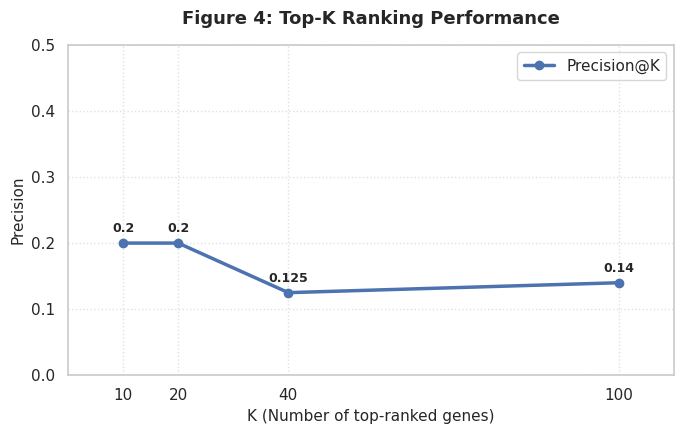

Figure saved to: /content/T2D_v10_ML_Results/figures/Figure_4_topk_performance.png
  k  hits  precision
 10     2      0.200
 20     4      0.200
 40     5      0.125
100    14      0.140


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path('/content/T2D_v10_ML_Results/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load actual results generated by the Colab analysis
results_path = Path('/content/T2D_v10_ML_Results/tables/precision_at_k.csv')
df = pd.read_csv(results_path)

ks = [10, 20, 40, 100]
plot_df = df[df['k'].isin(ks)].sort_values('k')

if set(plot_df['k']) != set(ks):
    raise ValueError("Some requested K values are missing from precision_at_k.csv")

plt.figure(figsize=(7, 4.5))
plt.plot(
    plot_df['k'],
    plot_df['precision'],
    marker='o',
    linewidth=2.5,
    label='Precision@K'
)

plt.xlim(0, 110)
plt.ylim(0, 0.5)
plt.xlabel('K (Number of top-ranked genes)', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.title('Figure 4: Top-K Ranking Performance',
          fontsize=13, fontweight='bold', pad=15)
plt.xticks(ks)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

for _, row in plot_df.iterrows():
    value = row['precision']
    plt.annotate(
        f"{value:.3f}".rstrip('0').rstrip('.'),
        (row['k'], value),
        xytext=(0, 8),
        textcoords='offset points',
        ha='center',
        fontweight='semibold',
        fontsize=9
    )

plt.tight_layout()
fig_path = FIG_DIR / 'Figure_4_topk_performance.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Figure saved to: {fig_path}")
print(plot_df[['k', 'hits', 'precision']].to_string(index=False))

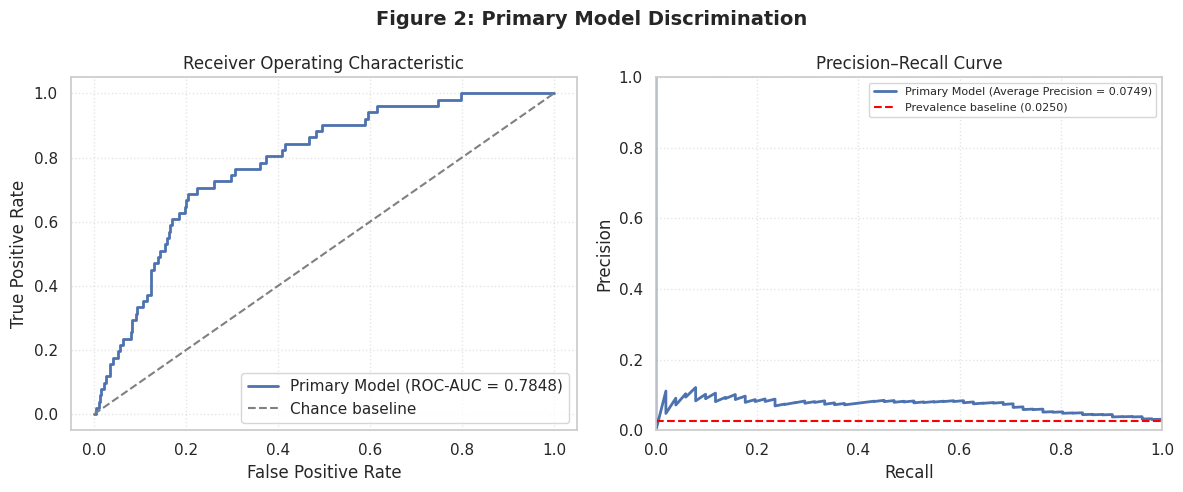

ROC-AUC: 0.784826
Average precision: 0.074881
Positive prevalence: 0.024976
Saved: /content/T2D_v10_ML_Results/figures/Figure_2_primary_model_discrimination.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Paths
BASE_DIR = Path('/content/T2D_v10_ML_Results')
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

OOF_PATH = BASE_DIR / 'tables' / \
    'oof_l2_logistic_regression_locked_primary.csv'

# Load actual out-of-fold predictions
oof = pd.read_csv(OOF_PATH)

required_cols = {'y_true', 'prediction'}
if not required_cols.issubset(oof.columns):
    raise ValueError(f"Expected columns: {required_cols}")

y_true = oof['y_true'].astype(int)
y_score = oof['prediction'].astype(float)

# Calculate metrics from predictions
roc_auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)
prevalence = y_true.mean()

fpr, tpr, _ = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    fpr, tpr, linewidth=2,
    label=f'Primary Model (ROC-AUC = {roc_auc:.4f})'
)
axes[0].plot(
    [0, 1], [0, 1], linestyle='--',
    color='gray', label='Chance baseline'
)
axes[0].set_title('Receiver Operating Characteristic')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.5)

axes[1].plot(
    recall, precision, linewidth=2,
    label=f'Primary Model (Average Precision = {pr_auc:.4f})'
)
axes[1].axhline(
    prevalence, linestyle='--', color='red',
    label=f'Prevalence baseline ({prevalence:.4f})'
)
axes[1].set_title('Precision–Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, linestyle=':', alpha=0.5)

fig.suptitle(
    'Figure 2: Primary Model Discrimination',
    fontsize=14, fontweight='bold'
)
fig.tight_layout()

save_path = FIG_DIR / 'Figure_2_primary_model_discrimination.png'
fig.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'ROC-AUC: {roc_auc:.6f}')
print(f'Average precision: {pr_auc:.6f}')
print(f'Positive prevalence: {prevalence:.6f}')
print(f'Saved: {save_path}')

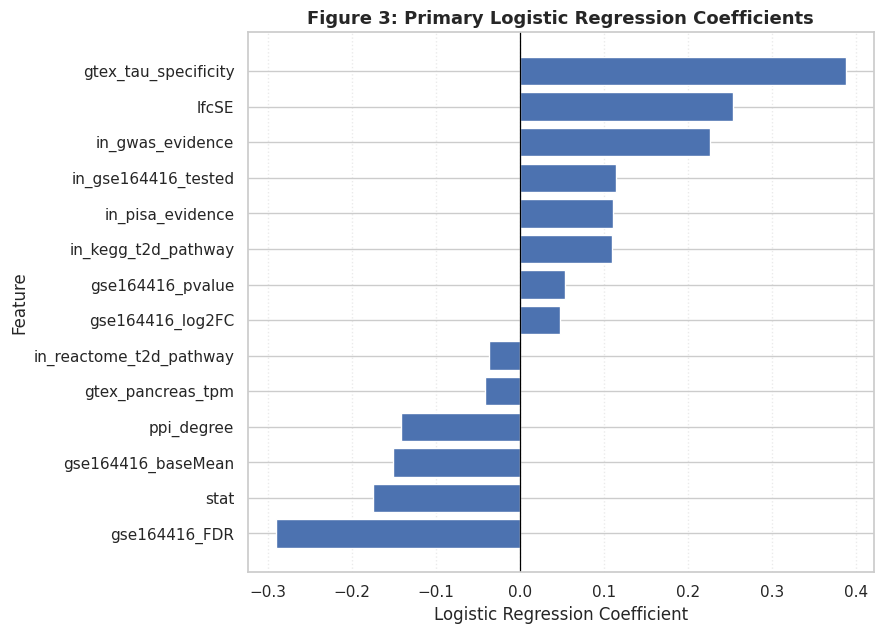

Saved: /content/T2D_v10_ML_Results/figures/Figure_3_logistic_regression_coefficients.png
                feature  coefficient
          gse164416_FDR    -0.289886
                   stat    -0.174451
     gse164416_baseMean    -0.150327
             ppi_degree    -0.141303
      gtex_pancreas_tpm    -0.041360
in_reactome_t2d_pathway    -0.037124
       gse164416_log2FC     0.047409
       gse164416_pvalue     0.053868
    in_kegg_t2d_pathway     0.109552
       in_pisa_evidence     0.110493
    in_gse164416_tested     0.113786
       in_gwas_evidence     0.225626
                  lfcSE     0.252946
   gtex_tau_specificity     0.387297


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Paths (aligned to workspace results directory)
BASE_DIR = Path('/content/T2D_v10_ML_Results')
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

COEF_PATH = BASE_DIR / 'tables' / 'locked_lr_coefficients.csv'

# Load coefficients from the fitted primary model
coef_df = pd.read_csv(COEF_PATH)

required_cols = {'feature', 'coefficient'}
if not required_cols.issubset(coef_df.columns):
    raise ValueError(f"Expected columns: {required_cols}")

coef_df = coef_df.dropna(subset=['feature', 'coefficient']).copy()
coef_df = coef_df.sort_values('coefficient')

# Plot signed logistic-regression coefficients
fig, ax = plt.subplots(figsize=(9, 6.5))

ax.barh(
    coef_df['feature'],
    coef_df['coefficient']
)
ax.axvline(0, color='black', linewidth=0.9)

ax.set_title(
    'Figure 3: Primary Logistic Regression Coefficients',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Logistic Regression Coefficient')
ax.set_ylabel('Feature')
ax.grid(axis='x', linestyle=':', alpha=0.4)

fig.tight_layout()

save_path = FIG_DIR / 'Figure_3_logistic_regression_coefficients.png'
fig.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Saved: {save_path}')
print(coef_df[['feature', 'coefficient']].to_string(index=False))